# PPDS - IA machine learning
## Tarea: Clasificación con un Perceptrón Multicapa (MLP) en PyTorch — Versión 2
### Diagnóstico de *underfitting* y *overfitting* con learning curves



---

### 🎯 Objetivos de aprendizaje

Al terminar esta tarea podrás:

1. Explicar con tus propias palabras qué es **underfitting** y qué es **overfitting**.
2. Dividir un dataset en **train / validation / test** y justificar para qué sirve cada parte.
3. Leer **learning curves** (curvas de aprendizaje) para diagnosticar si un modelo está subajustado, sobreajustado o bien ajustado.
4. Observar cómo la arquitectura y los hiperparámetros (capacidad, épocas, dropout, weight decay, learning rate, cantidad de datos, batch norm, activación) cambian ese diagnóstico.

### 🧭 Cómo funciona esta tarea

- El código del modelo, del entrenamiento y de las gráficas **ya está implementado** (Sección 5). No necesitas reescribirlo: solo cambias algunos valores marcados con `TODO`.
- Hay **una sección de train/validation split** (Sección 4) que **sí debes completar tú**, con guía y ejemplos.
- Hay **10 ejercicios**. En cada uno debes:
  1. **Correr** el experimento.
  2. **Observar** las curvas y los números.
  3. **Diagnosticar**: ¿*underfitting*, *overfitting* o modelo *"bueno"*? Siempre con evidencia numérica.
  4. **Responder** las preguntas y escribir una **conclusión**.
- Para escribir tus respuestas, haz doble clic en la celda de markdown **"📝 Tus respuestas"** de cada ejercicio.

> ⚠️ **Regla de oro:** un diagnóstico sin números no vale. Siempre cita valores de accuracy/loss de *train* y *validation*, y la brecha entre ambos.

### 📊 Rúbrica

| Parte | Puntos |
|---|---|
| Sección 4: train/validation split correcto + respuestas | 10 |
| Ejercicios 1 a 10 (8 pts c/u: 2 ejecución, 3 diagnóstico justificado con números, 3 respuestas y conclusión) | 80 |
| Reflexión final (Sección 7) | 10 |
| **Total** | **100** |

### 🗂️ Contenido

1. Teoría: generalización, underfitting y overfitting
2. Configuración del entorno
3. Dataset (MNIST)
4. **Train / validation / test split** (tu turno)
5. Código base (no modificar)
6. Ejercicios 1 a 10
7. Resumen y reflexión final

> 💡 Si no tienes GPU puedes ejecutar todo en CPU, pero los Ejercicios 3 y 5 tardan algo más (1-2 min). También puedes usar Google Colab. Los resultados pueden variar ligeramente entre equipos.

**Estudiante:** Douglas

**Fecha de ejecución:** 12 de noviembre de 2026


---
# 1. Teoría: generalización, underfitting y overfitting

El objetivo de un modelo de machine learning **no es memorizar los datos de entrenamiento**, sino **generalizar**: funcionar bien con datos que nunca ha visto.

## 🎓 La analogía de los tres estudiantes

Imagina que tres estudiantes se preparan para un examen de matemáticas. Tienen un libro con **100 ejercicios de práctica** (el conjunto de **entrenamiento**). Luego hacen un **simulacro** con ejercicios nuevos (el conjunto de **validación**) y finalmente presentan el **examen final** (el conjunto de **test**).

| Estudiante | Qué hizo | Práctica (train) | Simulacro con ejercicios nuevos (validation) | Diagnóstico |
|---|---|---|---|---|
| 😴 **A — "No aprendió"** | Estudió poco o con un método demasiado limitado; no logra captar ni lo básico. | ❌ Mala nota | ❌ Mala nota (parecida a la de práctica) | **Underfitting** |
| 🧠 **B — "Memorizó, pero no entendió"** | Se aprendió de memoria las respuestas de los 100 ejercicios, sin entender el concepto. | ✅ 100/100 | ❌ Mala nota: los ejercicios nuevos no se parecen a los que memorizó | **Overfitting** |
| 🎓 **C — "Entendió"** | Entendió los conceptos detrás de los ejercicios. | ✅ Buena nota | ✅ Buena nota (similar a la de práctica) | **Buen ajuste** |

La clave: el estudiante B **no aprendió nada útil**; solo memorizó las respuestas de los ejercicios de práctica. Su nota de práctica es engañosa. Por eso **nunca evaluamos un modelo solo con los datos con los que entrenó**.

## 🔍 Definiciones

- **Underfitting (subajuste):** el modelo es demasiado simple, está poco entrenado o está mal optimizado, y **no logra aprender ni siquiera los datos de entrenamiento**. El error es alto tanto en train como en validation (alto *bias*).
- **Overfitting (sobreajuste):** el modelo aprende tan bien los datos de entrenamiento (incluido su ruido y casos particulares) que **pierde capacidad de generalizar**. El error en train es muy bajo, pero en validation es mucho más alto (alta *varianza*).
- **Buen ajuste:** el modelo funciona bien en train **y** en validation, con una brecha pequeña entre ambos.

## 📈 Tabla de diagnóstico

| Señal que observas | Underfitting 😴 | Overfitting 🧠 | Modelo bueno 🎓 |
|---|---|---|---|
| **Train loss / accuracy** | Loss alta, accuracy baja | Loss muy baja (≈ 0), accuracy ≈ 100 % | Loss baja, accuracy alta |
| **Brecha train vs validation** | Pequeña (ambos malos) | **Grande** | Pequeña |
| **Val loss a lo largo de las épocas** | Alta; baja muy poco o se queda plana | Baja al inicio y luego **empieza a SUBIR** | Baja y se estabiliza |
| **Remedios típicos** | Más capacidad (más neuronas/capas), entrenar más épocas, ajustar learning rate, **reducir** la regularización | Más datos, dropout, weight decay, modelo más pequeño, early stopping | — |

> ⚠️ Los umbrales exactos dependen del problema. En MNIST, como referencia aproximada: un modelo lineal sencillo ya alcanza ~90 % de accuracy, así que un MLP muy por debajo de eso probablemente tiene underfitting. Una brecha train-val de varios puntos porcentuales, o una val loss que sube mientras la train loss baja, indica overfitting. **No existe un umbral mágico: justifica tu diagnóstico con los números y las curvas.**

## 📉 Learning curves (curvas de aprendizaje)

Una **learning curve** grafica la métrica (loss o accuracy) de **train** y de **validation** en cada época. Es la herramienta principal para diagnosticar. Ejecuta la celda siguiente para ver un **ejemplo sintético** (datos inventados, no es un entrenamiento real) de los tres casos:

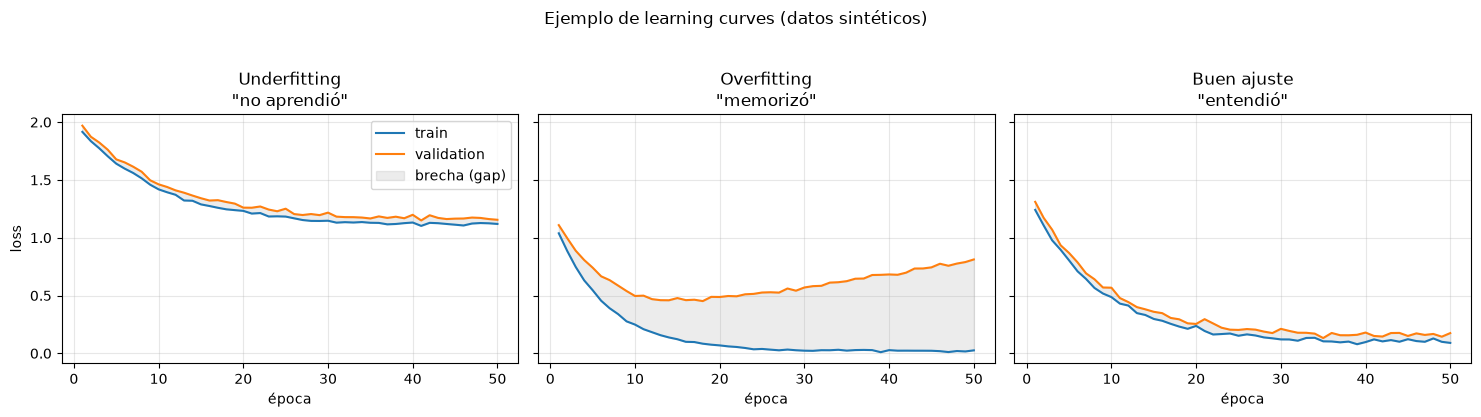

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Curvas SINTÉTICAS (inventadas) para aprender a leerlas
rng = np.random.default_rng(0)
ep = np.arange(1, 51)
noise = lambda s: rng.normal(0, s, size=ep.shape)

# 1) Underfitting: ambas curvas se quedan ALTAS y casi juntas
train_u = 1.10 + 0.90 * np.exp(-ep / 10) + noise(0.01)
val_u   = train_u + 0.05 + noise(0.01)

# 2) Overfitting: train baja casi a 0; val baja un rato y luego SUBE
train_o = 0.02 + 1.20 * np.exp(-ep / 6) + noise(0.005)
val_o   = 0.35 + 0.90 * np.exp(-ep / 6) + 0.012 * np.clip(ep - 12, 0, None) + noise(0.01)

# 3) Buen ajuste: ambas bajan, se estabilizan en un valor bajo y cerca una de otra
train_g = 0.10 + 1.30 * np.exp(-ep / 8) + noise(0.01)
val_g   = 0.16 + 1.30 * np.exp(-ep / 8) + noise(0.015)

curves = [
    ('Underfitting\n"no aprendió"', train_u, val_u),
    ('Overfitting\n"memorizó"',     train_o, val_o),
    ('Buen ajuste\n"entendió"',     train_g, val_g),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, tr, va) in zip(axes, curves):
    ax.plot(ep, tr, label='train')
    ax.plot(ep, va, label='validation')
    ax.fill_between(ep, tr, va, alpha=0.15, color='gray', label='brecha (gap)')
    ax.set_title(title)
    ax.set_xlabel('época')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('loss')
axes[0].legend()
plt.suptitle('Ejemplo de learning curves (datos sintéticos)', y=1.03)
plt.tight_layout()
plt.show()

### 🧐 Cómo leer las curvas (checklist de 3 preguntas)

Para cada experimento hazte estas tres preguntas, **en este orden**:

1. **¿Cómo está el rendimiento en *train*?** ¿La loss es baja y la accuracy alta? Si no, el modelo ni siquiera aprende los datos de entrenamiento → sospecha de **underfitting**.
2. **¿Qué tan grande es la brecha entre *train* y *validation*?** Si es grande → sospecha de **overfitting**.
3. **¿Qué hace la *val loss* a lo largo de las épocas?** Si baja y luego sube mientras la train loss sigue bajando → **overfitting** (el estudiante B empezó a memorizar). La línea punteada gris de nuestras gráficas marca la época con menor val loss.

Si train y validation son buenos y están cerca, y la val loss no sube → **modelo bueno**.

> 📝 *Nota:* la accuracy y la loss cuentan historias parecidas pero no idénticas. La **loss** es más sensible: a veces la accuracy de validation parece estable mientras la val loss ya está subiendo (el modelo se vuelve "demasiado seguro" de sus errores).

---
# 2. Configuración del entorno

Si estás en Colab o no tienes las librerías, descomenta la primera línea de la siguiente celda.

In [2]:
# !pip install torch torchvision pandas matplotlib

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split
from torchvision import datasets

SEED = 42

def set_seed(seed=SEED):
    """Fija las semillas para que los experimentos sean reproducibles."""
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE}")
# Limitar hilos evita sobrecarga en los mini-batches pequeños de CPU.
torch.set_num_threads(4)
import platform
print("Python:", platform.python_version(), "| hilos CPU:", torch.get_num_threads())


PyTorch 2.15.0+cpu | dispositivo: cpu
Python: 3.14.3 | hilos CPU: 4


---
# 3. Dataset: MNIST

**MNIST** contiene imágenes de 28×28 píxeles de dígitos escritos a mano (clases 0 a 9). Es fácil de cargar y procesar, ideal para estudiar MLPs.

Para que el **overfitting sea visible y los experimentos sean rápidos**, no usaremos las 60,000 imágenes de entrenamiento completas. Haremos lo siguiente:

- Tomaremos un **pool de 10,000 imágenes** al azar del set de entrenamiento oficial.
- En la **Sección 4** tú dividirás ese pool en **train (80 %)** y **validation (20 %)**.
- El set de **test oficial (10,000 imágenes)** se queda guardado y **solo se usará al final, en el Ejercicio 10**.

Pool: (10000, 1, 28, 28) | Test oficial: (10000, 1, 28, 28)
Muestras por clase en el pool: [993, 1074, 1016, 1042, 982, 914, 995, 1011, 1005, 968]


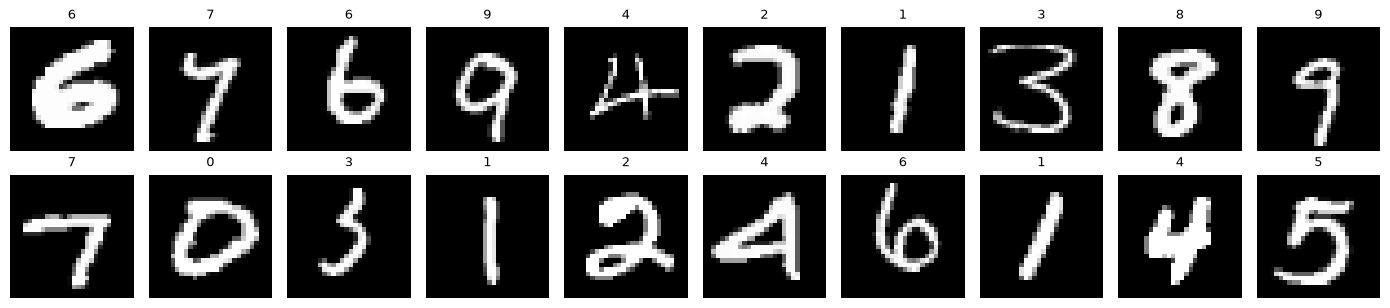

In [3]:
# Descarga (la primera vez) los datos oficiales de MNIST
full_train = datasets.MNIST(root='./data', train=True,  download=True)
full_test  = datasets.MNIST(root='./data', train=False, download=True)

MEAN, STD = 0.1307, 0.3081   # media y desviación estándar de MNIST

def to_tensors(mnist_ds, indices=None):
    """Convierte las imágenes a tensores normalizados con forma (N, 1, 28, 28)."""
    X = mnist_ds.data if indices is None else mnist_ds.data[indices]
    y = mnist_ds.targets if indices is None else mnist_ds.targets[indices]
    X = ((X.float() / 255.0) - MEAN) / STD
    return X.unsqueeze(1), y

# Pool de 10,000 imágenes elegidas al azar del set de entrenamiento oficial
POOL_SIZE = 10_000
g = torch.Generator().manual_seed(SEED)
pool_idx = torch.randperm(len(full_train), generator=g)[:POOL_SIZE]
X_pool, y_pool = to_tensors(full_train, pool_idx)
pool_ds = TensorDataset(X_pool, y_pool)

# Set de test oficial (NO lo toques hasta el Ejercicio 10)
X_test, y_test = to_tensors(full_test)
test_ds = TensorDataset(X_test, y_test)

print(f"Pool: {tuple(X_pool.shape)} | Test oficial: {tuple(X_test.shape)}")
print("Muestras por clase en el pool:", torch.bincount(y_pool).tolist())

# Vistazo a algunas imágenes
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_pool[i, 0], cmap='gray')
    ax.set_title(int(y_pool[i]), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

---
# 4. Train / validation / test split (¡tu turno!)

## ¿Por qué dividir los datos?

Volvamos a nuestra analogía:

| Conjunto | En la analogía | Para qué sirve |
|---|---|---|
| **Train** | Los 100 ejercicios de práctica | El modelo **aprende** de estos datos (se ajustan los pesos). |
| **Validation** | El simulacro con ejercicios nuevos | Sirve para **diagnosticar** (under/overfitting) y **elegir hiperparámetros**. El modelo no se entrena con estos datos. |
| **Test** | El examen final | Se usa **una sola vez** al final para estimar el rendimiento real. Si lo usas para tomar decisiones, deja de ser un examen sorpresa. |

Si evaluáramos solo en train, el estudiante B (el que memoriza) parecería un genio. La validación nos permite **detectarlo**.

## Cómo hacer el split en PyTorch

La herramienta estándar es [`torch.utils.data.random_split`](https://pytorch.org/docs/stable/data.html#torch.utils.data.random_split). Recibe un dataset y una lista con el **tamaño** de cada parte (deben sumar exactamente el total), y devuelve objetos `Subset`:

```python
from torch.utils.data import random_split

n_train = int(0.8 * len(dataset))     # 80 % para entrenar
n_val   = len(dataset) - n_train      # el resto para validar (así la suma siempre es exacta)

train_part, val_part = random_split(
    dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42),   # para que el split sea reproducible
)
```

Puntos importantes:
- El split es **aleatorio** (los datos pueden venir ordenados por clase o por fecha, y no queremos sesgos).
- Fijamos una **semilla** para poder reproducir el mismo split.
- Train y validation **no deben compartir ninguna muestra** (si no, es como darle al estudiante las preguntas del examen).

**Referencias útiles:**
- [Documentación de `random_split`](https://pytorch.org/docs/stable/data.html#torch.utils.data.random_split)
- Alternativa con scikit-learn: [`sklearn.model_selection.train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) (permite `stratify=y` para mantener la proporción de clases).

Primero corre este **ejemplo guiado** con un dataset de juguete (ya funciona, solo léelo):

In [4]:
# --- EJEMPLO GUIADO (ya funciona; solo léelo y córrelo) ---
# Dataset de juguete: 100 muestras con 3 features y etiquetas 0/1
X_toy = torch.randn(100, 3)
y_toy = torch.randint(0, 2, (100,))
toy_ds = TensorDataset(X_toy, y_toy)

n_toy_train = int(0.8 * len(toy_ds))      # 80
n_toy_val   = len(toy_ds) - n_toy_train   # 20

toy_train, toy_val = random_split(
    toy_ds,
    [n_toy_train, n_toy_val],
    generator=torch.Generator().manual_seed(SEED),
)

print("Tamaños:", len(toy_train), len(toy_val))
print("Primeros índices de train:", toy_train.indices[:5])
print("¿Hay muestras en común?:", len(set(toy_train.indices) & set(toy_val.indices)) > 0)

Tamaños: 80 20
Primeros índices de train: [42, 96, 62, 98, 46]
¿Hay muestras en común?: False


## ✍️ Tu tarea

Divide `pool_ds` (10,000 muestras) en:
- `train_ds`: **80 %** → 8,000 muestras
- `val_ds`: **20 %** → 2,000 muestras

Completa los espacios `____` de la celda siguiente (mientras estén sin completar verás un `NameError`; es normal).

<details>
<summary>💡 Pista (haz clic si te atascas)</summary>

Sigue exactamente el ejemplo guiado: calcula `n_train` como el 80 % del total, `n_val` como el resto, y pásale a `random_split` el dataset a dividir y la lista `[n_train, n_val]`.
</details>

In [5]:
# División reproducible del pool, sin compartir muestras.
n_total = len(pool_ds)
n_train = int(0.8 * n_total)
n_val = n_total - n_train
train_ds, val_ds = random_split(
    pool_ds, [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED),
)
print(f"Train: {len(train_ds)} | Validation: {len(val_ds)} | Test (guardado): {len(test_ds)}")


Train: 8000 | Validation: 2000 | Test (guardado): 10000


In [6]:
# --- VERIFICACIÓN (no modificar) ---
assert len(train_ds) + len(val_ds) == len(pool_ds), "Train + validation debe sumar 10,000 muestras."
assert len(train_ds) == 8000 and len(val_ds) == 2000, "Se esperaban 8,000 muestras en train y 2,000 en validation."
assert len(set(train_ds.indices) & set(val_ds.indices)) == 0, "¡Train y validation comparten muestras!"
print("✅ Split correcto.")
print("Distribución de clases en train:     ", torch.bincount(y_pool[train_ds.indices]).tolist())
print("Distribución de clases en validation:", torch.bincount(y_pool[val_ds.indices]).tolist())

✅ Split correcto.
Distribución de clases en train:      [801, 879, 786, 837, 771, 718, 800, 817, 817, 774]
Distribución de clases en validation: [192, 195, 230, 205, 211, 196, 195, 194, 188, 194]


### 📝 Tus respuestas — Sección 4

1. Uso train como los ejercicios de práctica: con ellos el estudiante aprende.
   Validation es el simulacro con preguntas nuevas; me permite comprobar si
   entendió y elegir cómo entrenarlo antes del examen final.
2. No elijo hiperparámetros con test porque terminaría adaptando el modelo al
   examen final. Su resultado dejaría de estimar el desempeño en datos nuevos.
3. Divido al azar para evitar que el orden produzca grupos distintos. Si las
   imágenes estuvieran ordenadas por dígito, train podría quedarse sin algunas
   clases y validation contener sobre todo las últimas. Fijo la semilla 42 para
   reproducir el split. La verificación confirma 8,000/2,000 y cero solapamiento.
4. Estratificar significa conservar aproximadamente la proporción de cada clase
   en ambos grupos. Es especialmente útil con clases escasas o desbalanceadas.
   Aquí uso el split aleatorio solicitado; no lo confundo con uno estratificado.


---
# 5. Código base (no modificar)

Esta sección contiene todo lo necesario para entrenar y graficar. **Ejecuta las celdas sin modificarlas.** Léelas con calma: es una buena oportunidad para entender cómo se arma un MLP y un loop de entrenamiento.

### Hiperparámetros disponibles

Todos los experimentos se definen con un diccionario de configuración, que se crea con `make_config(**cambios)`. Los valores **por defecto** (baseline) son:

| Hiperparámetro | Valor por defecto | Descripción |
|---|---|---|
| `hidden_sizes` | `[128, 64]` | Neuronas de cada capa oculta (arquitectura). |
| `activation` | `'relu'` | `'relu'`, `'tanh'`, `'leaky_relu'` o `'gelu'`. |
| `dropout` | `0.0` | Probabilidad de apagar neuronas durante el entrenamiento. |
| `batch_norm` | `False` | Si se usa Batch Normalization después de cada capa lineal. |
| `optimizer` | `'adam'` | `'adam'`, `'adamw'` o `'sgd'` (con momentum 0.9). |
| `lr` | `1e-3` | Learning rate. |
| `weight_decay` | `0.0` | Penalización L2 sobre los pesos. |
| `batch_size` | `64` | Tamaño del mini-batch. |
| `epochs` | `30` | Número de épocas. |
| `n_train` | `None` | Si es un entero, usa solo las primeras `n_train` muestras de train. |

> 💡 En cada época medimos la loss y la accuracy de **train** y de **validation** con el modelo en modo evaluación (sin dropout), para que las learning curves sean comparables.

In [7]:
class MLP(nn.Module):
    """Perceptrón multicapa configurable: [Linear -> (BatchNorm) -> Activación -> (Dropout)] x N -> Linear."""

    def __init__(self, input_dim=784, hidden_sizes=(128, 64), num_classes=10,
                 activation='relu', dropout=0.0, batch_norm=False):
        super().__init__()
        activations = {
            'relu': nn.ReLU,
            'tanh': nn.Tanh,
            'leaky_relu': nn.LeakyReLU,
            'gelu': nn.GELU,
        }
        if activation not in activations:
            raise ValueError(f"Activación desconocida: {activation}. Opciones: {list(activations)}")

        layers = [nn.Flatten()]            # (N, 1, 28, 28) -> (N, 784)
        prev = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(activations[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))   # salida: logits de 10 clases
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    """Número de parámetros entrenables del modelo."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Prueba rápida de la arquitectura baseline
print(MLP())
print("Parámetros:", count_params(MLP()))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parámetros: 109386


In [8]:
# ---------- Configuración y entrenamiento ----------
BASE_CONFIG = dict(
    hidden_sizes=[128, 64],
    activation='relu',
    dropout=0.0,
    batch_norm=False,
    optimizer='adam',
    lr=1e-3,
    weight_decay=0.0,
    batch_size=64,
    epochs=30,
    n_train=None,
)

RESULTS = {}   # aquí se guardan los resultados de todos tus experimentos


def make_config(**changes):
    """Crea una configuración a partir del baseline, cambiando solo lo que indiques."""
    unknown = set(changes) - set(BASE_CONFIG)
    if unknown:
        raise ValueError(f"Hiperparámetros desconocidos: {unknown}. Válidos: {list(BASE_CONFIG)}")
    cfg = {k: (list(v) if isinstance(v, list) else v) for k, v in BASE_CONFIG.items()}
    cfg.update(changes)
    return cfg


def build_optimizer(model, cfg):
    name = cfg['optimizer'].lower()
    params = model.parameters()
    if name == 'adam':
        return torch.optim.Adam(params, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    if name == 'adamw':
        return torch.optim.AdamW(params, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    if name == 'sgd':
        return torch.optim.SGD(params, lr=cfg['lr'], momentum=0.9, weight_decay=cfg['weight_decay'])
    raise ValueError(f"Optimizador desconocido: {name}")


@torch.no_grad()
def evaluate(model, loader):
    """Devuelve (loss, accuracy) promedio sobre un DataLoader, con el modelo en modo evaluación."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        logits = model(X)
        total_loss += F.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train_model(cfg, name, verbose=True):
    """Entrena un MLP con la configuración `cfg`.

    Guarda el historial en RESULTS[name] y devuelve (modelo, historial).
    El historial tiene: train_loss, val_loss, train_acc, val_acc (un valor por época).
    """
    if 'train_ds' not in globals() or 'val_ds' not in globals():
        raise RuntimeError("Primero completa la Sección 4 (train/validation split).")

    set_seed(SEED)   # misma semilla en cada experimento -> comparaciones justas

    train_data = train_ds if cfg['n_train'] is None else Subset(train_ds, range(cfg['n_train']))
    if len(train_data) < cfg['batch_size']:
        raise ValueError("n_train debe ser al menos igual al batch_size.")

    # drop_last=True evita un último batch de tamaño 1 (problemático para BatchNorm)
    train_loader = DataLoader(train_data, batch_size=cfg['batch_size'], shuffle=True, drop_last=True)
    train_eval_loader = DataLoader(train_data, batch_size=2000, shuffle=False)
    val_loader = DataLoader(val_ds, batch_size=2000, shuffle=False)

    model = MLP(hidden_sizes=cfg['hidden_sizes'], activation=cfg['activation'],
                dropout=cfg['dropout'], batch_norm=cfg['batch_norm']).to(DEVICE)
    optimizer = build_optimizer(model, cfg)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    t0 = time.time()

    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        for X, y in train_loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(X), y)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate(model, train_eval_loader)
        va_loss, va_acc = evaluate(model, val_loader)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        if verbose and (epoch == 1 or epoch % 5 == 0 or epoch == cfg['epochs']):
            print(f"[{name}] época {epoch:3d}/{cfg['epochs']} | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")

    if verbose:
        print(f"Parámetros: {count_params(model):,} | tiempo: {time.time() - t0:.1f} s")

    RESULTS[name] = {'config': cfg, 'history': history}
    return model, history

In [9]:
# ---------- Gráficas y resúmenes ----------
def best_epoch(history):
    """Época (empezando en 1) con la menor validation loss."""
    vl = np.array(history['val_loss'], dtype=float)
    if np.all(np.isnan(vl)):
        return 1
    return int(np.nanargmin(vl)) + 1


def plot_learning_curves(history, title='Learning curves'):
    """Grafica loss y accuracy de train y validation. La línea gris marca la época con menor val loss."""
    epochs = range(1, len(history['train_loss']) + 1)
    b = best_epoch(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history['train_loss'], label='train')
    axes[0].plot(epochs, history['val_loss'], label='validation')
    axes[0].axvline(b, color='gray', linestyle='--', alpha=0.7, label=f'mín. val loss (época {b})')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('época')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history['train_acc'], label='train')
    axes[1].plot(epochs, history['val_acc'], label='validation')
    axes[1].axvline(b, color='gray', linestyle='--', alpha=0.7)
    axes[1].set_title('Accuracy')
    axes[1].set_xlabel('época')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def print_summary(history):
    """Imprime los números clave para diagnosticar (¡úsalos como evidencia!)."""
    tr_acc, va_acc = history['train_acc'][-1], history['val_acc'][-1]
    tr_loss, va_loss = history['train_loss'][-1], history['val_loss'][-1]
    b = best_epoch(history)
    print(f"Accuracy final -> train: {tr_acc:.4f} | val: {va_acc:.4f} | brecha (train - val): {100 * (tr_acc - va_acc):+.2f} pts")
    print(f"Loss final     -> train: {tr_loss:.4f} | val: {va_loss:.4f}")
    print(f"Mínimo de val loss: {history['val_loss'][b - 1]:.4f} en la época {b} de {len(history['val_loss'])}")


def compare_runs(names, title='Comparación de experimentos'):
    """Superpone las curvas de varios experimentos (punteada = train, continua = validation)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, name in enumerate(names):
        h = RESULTS[name]['history']
        ep = range(1, len(h['train_loss']) + 1)
        c = f'C{i}'
        axes[0].plot(ep, h['train_loss'], color=c, linestyle='--', alpha=0.8)
        axes[0].plot(ep, h['val_loss'], color=c, label=name)
        axes[1].plot(ep, h['train_acc'], color=c, linestyle='--', alpha=0.8)
        axes[1].plot(ep, h['val_acc'], color=c, label=name)
    axes[0].set_title('Loss  (punteada = train, continua = validation)')
    axes[1].set_title('Accuracy  (punteada = train, continua = validation)')
    for ax in axes:
        ax.set_xlabel('época')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def results_table(prefix=None):
    """Tabla con los resultados finales de los experimentos (opcionalmente filtrados por prefijo)."""
    rows = []
    for name, r in RESULTS.items():
        if prefix and not name.startswith(prefix):
            continue
        h = r['history']
        rows.append({
            'experimento': name,
            'train_acc': h['train_acc'][-1],
            'val_acc': h['val_acc'][-1],
            'brecha_acc_pts': 100 * (h['train_acc'][-1] - h['val_acc'][-1]),
            'train_loss': h['train_loss'][-1],
            'val_loss': h['val_loss'][-1],
            'mejor_epoca': best_epoch(h),
            'min_val_loss': float(np.nanmin(h['val_loss'])) if not np.all(np.isnan(h['val_loss'])) else float('nan'),
        })
    return pd.DataFrame(rows).set_index('experimento').round(4)


print("✅ Código base cargado. Uso básico:")
print("   cfg = make_config(dropout=0.3)")
print("   model, hist = train_model(cfg, 'mi_experimento')")
print("   plot_learning_curves(hist, 'Mi experimento'); print_summary(hist)")

✅ Código base cargado. Uso básico:
   cfg = make_config(dropout=0.3)
   model, hist = train_model(cfg, 'mi_experimento')
   plot_learning_curves(hist, 'Mi experimento'); print_summary(hist)


---
# 6. Ejercicios

En cada ejercicio escribirás tu **diagnóstico** con esta plantilla:

> **Diagnóstico:** _Underfitting_ / _Overfitting_ / _Modelo bueno_ (escoge uno)
> **Evidencia numérica:** valores de train/val y brecha
> **Respuestas y conclusión**

Recuerda el checklist: (1) ¿cómo está train? (2) ¿qué tan grande es la brecha? (3) ¿qué hace la val loss con las épocas?

## Ejercicio 1 — Baseline: tu punto de referencia

**Contexto:** antes de cambiar cosas necesitamos un punto de partida. La arquitectura baseline es `784 → 128 → 64 → 10` con ReLU, Adam (lr = 1e-3), batch de 64 y 30 épocas, sin ninguna regularización.

**Qué hacer:** ejecuta la celda sin modificarla. Anota los números: serán tu referencia en los demás ejercicios.

{'hidden_sizes': [128, 64], 'activation': 'relu', 'dropout': 0.0, 'batch_norm': False, 'optimizer': 'adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 64, 'epochs': 30, 'n_train': None}
[ex1_baseline] época   1/30 | train loss 0.3094 acc 0.9097 | val loss 0.3343 acc 0.9010


[ex1_baseline] época   5/30 | train loss 0.0796 acc 0.9794 | val loss 0.1821 acc 0.9520


[ex1_baseline] época  10/30 | train loss 0.0192 acc 0.9965 | val loss 0.2053 acc 0.9475


[ex1_baseline] época  15/30 | train loss 0.0040 acc 0.9995 | val loss 0.2045 acc 0.9550


[ex1_baseline] época  20/30 | train loss 0.0010 acc 1.0000 | val loss 0.2194 acc 0.9575


[ex1_baseline] época  25/30 | train loss 0.0005 acc 1.0000 | val loss 0.2337 acc 0.9585


[ex1_baseline] época  30/30 | train loss 0.0003 acc 1.0000 | val loss 0.2451 acc 0.9585
Parámetros: 109,386 | tiempo: 4.8 s


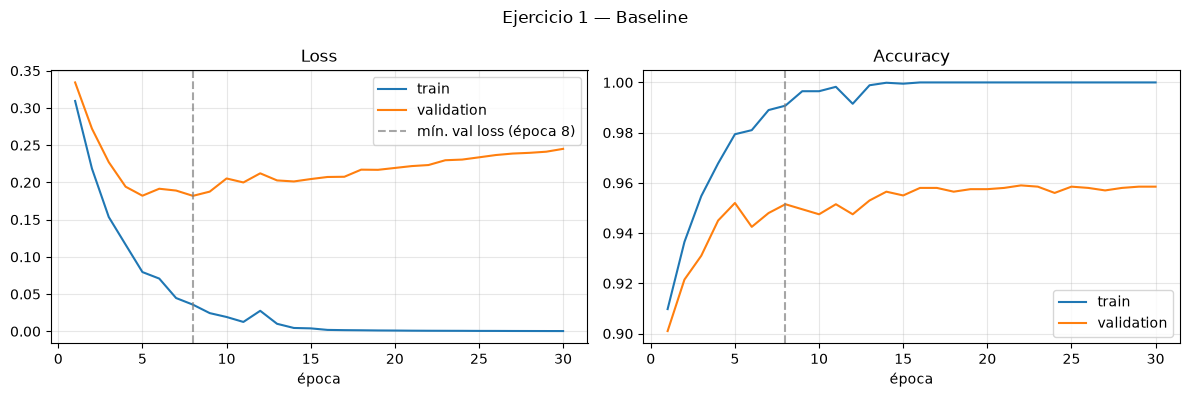

Accuracy final -> train: 1.0000 | val: 0.9585 | brecha (train - val): +4.15 pts
Loss final     -> train: 0.0003 | val: 0.2451
Mínimo de val loss: 0.1820 en la época 8 de 30


In [10]:
cfg = make_config()      # todos los valores por defecto
print(cfg)

model, hist = train_model(cfg, 'ex1_baseline')
plot_learning_curves(hist, 'Ejercicio 1 — Baseline')
print_summary(hist)

**Preguntas:**
1. ¿Qué accuracy tiene el modelo en train y en validation? ¿Qué tan grande es la brecha?
2. ¿La val loss baja durante todas las épocas o hay un punto a partir del cual sube? ¿En qué época?
3. Usando la analogía de los estudiantes, ¿a cuál se parece este modelo?

### 📝 Tus respuestas — Ejercicio 1

**Diagnóstico: Overfitting.**

**Evidencia:** train acc **100.00 %**, val acc **95.85 %**, brecha **+4.15 pp**; train loss **0.0003**, val loss **0.2451**. Mínima val loss: **0.1820**, época **8**.

1. Obtengo 100.00 % en train y
   95.85 % en validation, con 4.15 pp de brecha.
2. La menor val loss aparece en la época 8. Después
   oscila y termina en 0.2451, mientras la train loss
   cae a 0.0003; no mejora durante todo el entrenamiento.
3. Se parece al estudiante B: llega a resolver toda la práctica, pero esa mejora
   no se traslada por igual a preguntas nuevas.

**Conclusión:** El baseline aprende bien, pero memoriza parte del entrenamiento.
La validación conserva buena accuracy; el aumento de su loss evidencia sobreajuste.


---
## Ejercicio 2 — Capacidad insuficiente (¿cómo se ve el underfitting?)

**Contexto:** la *capacidad* de un modelo es qué tan complejas son las funciones que puede representar. Con muy pocas neuronas, el modelo tiene que comprimir toda la información de la imagen en muy pocos números.

**Parte A — Ya está dado.** Entrenamos un MLP con **una sola capa oculta de 2 neuronas**.

[ex2_underfit] época   1/30 | train loss 1.9971 acc 0.1779 | val loss 2.0114 acc 0.1780


[ex2_underfit] época   5/30 | train loss 1.5032 acc 0.4644 | val loss 1.5192 acc 0.4580


[ex2_underfit] época  10/30 | train loss 1.2669 acc 0.5489 | val loss 1.2825 acc 0.5540


[ex2_underfit] época  15/30 | train loss 1.1430 acc 0.6296 | val loss 1.1790 acc 0.6125


[ex2_underfit] época  20/30 | train loss 1.0826 acc 0.6388 | val loss 1.1302 acc 0.6215


[ex2_underfit] época  25/30 | train loss 1.0399 acc 0.6544 | val loss 1.0939 acc 0.6325


[ex2_underfit] época  30/30 | train loss 1.0136 acc 0.6576 | val loss 1.0735 acc 0.6380
Parámetros: 1,600 | tiempo: 3.5 s
Parámetros: 1600


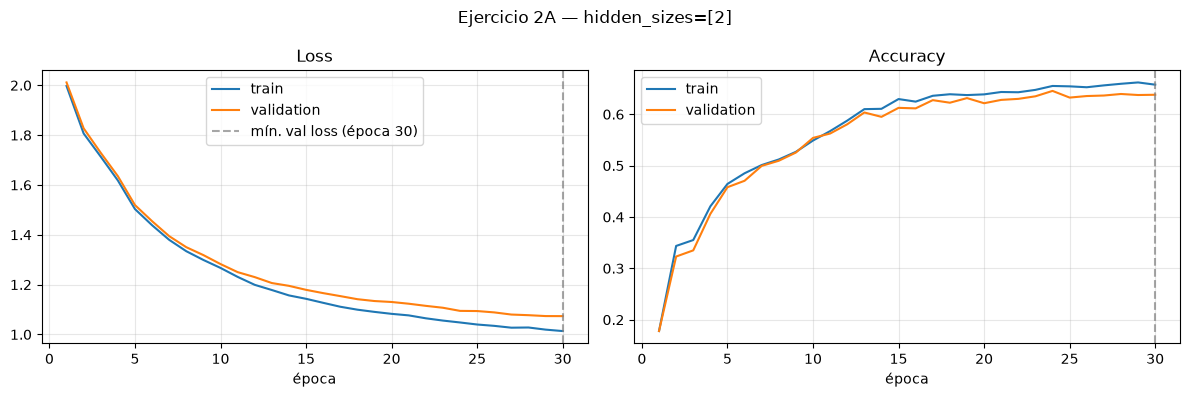

Accuracy final -> train: 0.6576 | val: 0.6380 | brecha (train - val): +1.96 pts
Loss final     -> train: 1.0136 | val: 1.0735
Mínimo de val loss: 1.0735 en la época 30 de 30


In [11]:
cfg = make_config(hidden_sizes=[2])    # una capa oculta con solo 2 neuronas
model, hist = train_model(cfg, 'ex2_underfit')
print("Parámetros:", count_params(model))
plot_learning_curves(hist, 'Ejercicio 2A — hidden_sizes=[2]')
print_summary(hist)

**Parte B — Tu cambio.** ¿Cuántas neuronas necesita el modelo para que el problema desaparezca? Modifica la lista `sizes` (marcada con `TODO`) y ejecuta la celda.

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex2_h4,0.8674,0.8515,1.5875,0.4409,0.5668,29,0.5601
ex2_h8,0.9412,0.8945,4.6750,0.2110,0.3818,20,0.3700
ex2_h16,0.9772,0.9200,5.7250,0.0893,0.3001,20,0.2761
ex2_h64,1.0000,0.9490,5.1000,0.0028,0.2286,13,0.1814
ex2_h256,1.0000,0.9585,4.1500,0.0005,0.1953,8,0.1572


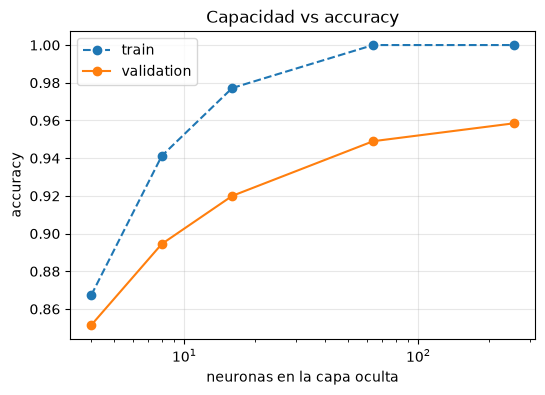

In [12]:
sizes = [4, 8, 16, 64, 256]    # TODO: prueba otros tamaños (p. ej. agrega 8 o 256)
sizes = sorted(sizes)

for s in sizes:
    train_model(make_config(hidden_sizes=[s]), f'ex2_h{s}', verbose=False)

names = [f'ex2_h{s}' for s in sizes]
tab = results_table().loc[names]
display(tab)

plt.figure(figsize=(6, 4))
plt.plot(sizes, tab['train_acc'], 'o--', label='train')
plt.plot(sizes, tab['val_acc'], 'o-', label='validation')
plt.xscale('log')
plt.xlabel('neuronas en la capa oculta')
plt.ylabel('accuracy')
plt.title('Capacidad vs accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Preguntas:**
1. En la Parte A, ¿qué accuracy tiene el modelo en train? ¿Y en validation? ¿Cómo es la brecha?
2. ¿Por qué decimos que este modelo no está aprendiendo "ni siquiera lo básico"? ¿A cuál estudiante de la analogía se parece?
3. En la Parte B, ¿a partir de qué tamaño deja de haber underfitting? ¿Cómo lo decides con los números?
4. ¿Qué ocurre con la brecha train-val conforme crece la capacidad?

### 📝 Tus respuestas — Ejercicio 2

**Diagnóstico Parte A: Underfitting.**

**Evidencia Parte A:** train acc **65.76 %**, val acc **63.80 %**, brecha **+1.96 pp**; train loss **1.0136**, val loss **1.0735**. Mínima val loss: **1.0735**, época **30**.

**Parte B:**

| Configuración | Diagnóstico | Train acc | Val acc | Brecha (pp) | Train loss | Val loss |
|---|---|---:|---:|---:|---:|---:|
| 4 | Underfitting | 86.74 % | 85.15 % | +1.59 | 0.4409 | 0.5668 |
| 8 | Underfitting relativo; empieza sobreajuste | 94.12 % | 89.45 % | +4.68 | 0.2110 | 0.3818 |
| 16 | Overfitting | 97.72 % | 92.00 % | +5.72 | 0.0893 | 0.3001 |
| 64 | Overfitting | 100.00 % | 94.90 % | +5.10 | 0.0028 | 0.2286 |
| 256 | Overfitting | 100.00 % | 95.85 % | +4.15 | 0.0005 | 0.1953 |


1. Con dos neuronas obtengo 65.76 % en train y
   63.80 % en validation. La brecha es pequeña
   (1.96 pp), pero ambos resultados son bajos.
2. La train loss de 1.0136 indica que ni siquiera
   ajusta bien la práctica. Se parece al estudiante A; dos neuronas limitan mucho
   la representación de los diez dígitos. No significa que no aprendió nada.
3. Considero que desde 16 neuronas desaparece la limitación más evidente:
   train llega a 97.72 %, frente a
   94.12 % con ocho. No hay un tamaño mágico:
   con 16 ya aparece sobreajuste y con 64/256 train llega al 100 %.
4. La brecha no crece de forma monótona: pasa por
   1.59, 4.68, 5.72, 5.10, 4.15 pp.
   Más capacidad primero resuelve la falta de ajuste, pero también permite memorizar.

**Conclusión:** Una brecha pequeña no basta: con cuatro neuronas ambos grupos
rinden peor. Aumentar capacidad mejora el aprendizaje, aunque después exige regularización.


---
## Ejercicio 3 — Capacidad excesiva (¿cómo se ve el overfitting?)

**Contexto:** ahora vamos al extremo contrario. Usaremos un modelo **mucho más grande** (3 capas ocultas de 1024 neuronas) con solo 8,000 imágenes de entrenamiento. Es como darle al estudiante B una memoria enorme y pocos ejercicios.

**Qué hacer:** ejecuta la celda (puede tardar 1-2 minutos en CPU). Requiere haber corrido el Ejercicio 1 para la comparación.

[ex3_big] época   1/30 | train loss 0.2259 acc 0.9263 | val loss 0.2739 acc 0.9200


[ex3_big] época   5/30 | train loss 0.0834 acc 0.9731 | val loss 0.2066 acc 0.9505


[ex3_big] época  10/30 | train loss 0.0159 acc 0.9951 | val loss 0.1920 acc 0.9625


[ex3_big] época  15/30 | train loss 0.0252 acc 0.9926 | val loss 0.3048 acc 0.9565


[ex3_big] época  20/30 | train loss 0.0692 acc 0.9832 | val loss 0.3808 acc 0.9425


[ex3_big] época  25/30 | train loss 0.0073 acc 0.9984 | val loss 0.2119 acc 0.9650


[ex3_big] época  30/30 | train loss 0.0110 acc 0.9965 | val loss 0.2784 acc 0.9615
Parámetros: 2,913,290 | tiempo: 43.9 s
Parámetros: 2,913,290


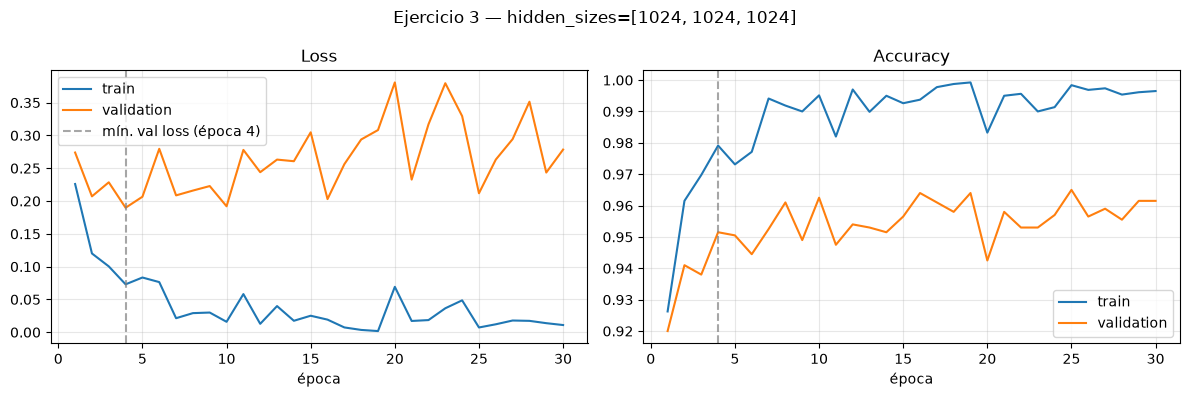

Accuracy final -> train: 0.9965 | val: 0.9615 | brecha (train - val): +3.50 pts
Loss final     -> train: 0.0110 | val: 0.2784
Mínimo de val loss: 0.1898 en la época 4 de 30


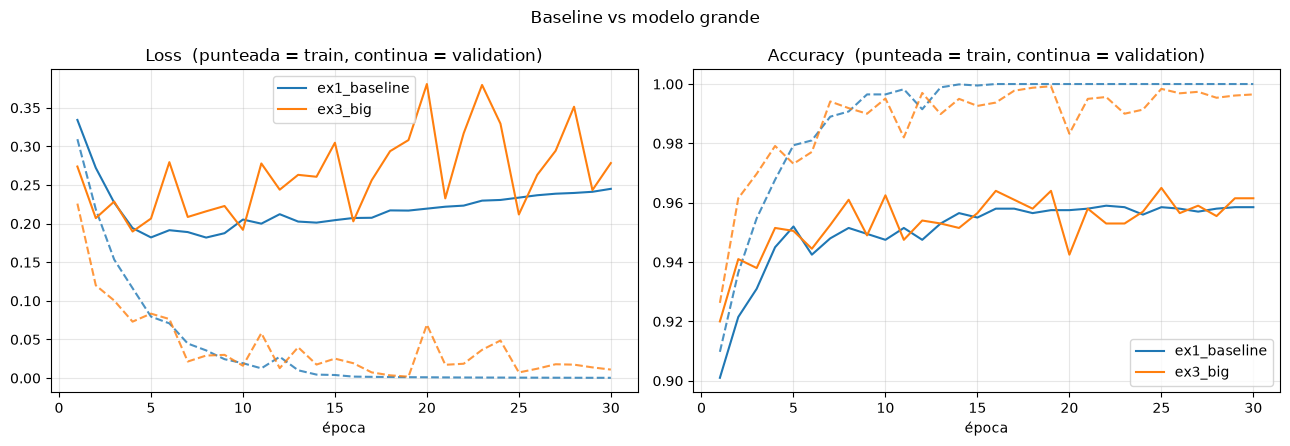

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex1_baseline,1.0000,0.9585,4.1500,0.0003,0.2451,8,0.1820
ex2_underfit,0.6576,0.6380,1.9625,1.0136,1.0735,30,1.0735
ex2_h4,0.8674,0.8515,1.5875,0.4409,0.5668,29,0.5601
ex2_h8,0.9412,0.8945,4.6750,0.2110,0.3818,20,0.3700
ex2_h16,0.9772,0.9200,5.7250,0.0893,0.3001,20,0.2761
ex2_h64,1.0000,0.9490,5.1000,0.0028,0.2286,13,0.1814
ex2_h256,1.0000,0.9585,4.1500,0.0005,0.1953,8,0.1572
ex3_big,0.9965,0.9615,3.5000,0.0110,0.2784,4,0.1898


In [13]:
cfg = make_config(hidden_sizes=[1024, 1024, 1024])
model, hist = train_model(cfg, 'ex3_big')
print("Parámetros:", f"{count_params(model):,}")
plot_learning_curves(hist, 'Ejercicio 3 — hidden_sizes=[1024, 1024, 1024]')
print_summary(hist)

# Comparación con el baseline
compare_runs(['ex1_baseline', 'ex3_big'], 'Baseline vs modelo grande')
display(results_table('ex'))

**Preguntas:**
1. Compara con el baseline: ¿cambió la train accuracy? ¿Y la val accuracy? ¿Y la brecha?
2. ¿Qué pasa con la **val loss** a medida que avanzan las épocas, comparado con la train loss? ¿En qué época está su mínimo?
3. ¿Por qué un modelo con más parámetros puede "memorizar" más fácilmente un dataset pequeño? Explícalo con la analogía.
4. Compara la val accuracy final con la **época en la que la val loss fue mínima** (línea gris). Aunque la accuracy final no empeore, ¿qué te dice la val loss sobre lo que pasó después de esa época? ¿Por qué la accuracy puede "esconder" un overfitting que la loss sí muestra?

### 📝 Tus respuestas — Ejercicio 3

**Diagnóstico: Overfitting.**

**Evidencia:** train acc **99.65 %**, val acc **96.15 %**, brecha **+3.50 pp**; train loss **0.0110**, val loss **0.2784**. Mínima val loss: **0.1898**, época **4**.

1. Frente al baseline, train cambia de 100.00 %
   a 99.65 % y validation de
   95.85 % a 96.15 %.
   La brecha pasa de 4.15 a 3.50 pp:
   en esta ejecución no aumentó. Tener más parámetros no garantiza una brecha mayor.
2. La val loss tiene su mínimo en la época 4
   (0.1898) y termina más alta
   (0.2784), con oscilaciones; la train loss final
   permanece muy baja (0.0110).
3. Los 2,913,290 parámetros permiten representar muchos detalles de solo 8,000
   imágenes. Es el estudiante B con suficiente memoria para recordar particularidades.
4. En el mínimo de val loss, la val accuracy era
   95.15 %; al final es
   96.15 %. La accuracy solo cuenta aciertos;
   la loss también penaliza la confianza de los errores. Por eso una accuracy
   parecida o mejor puede ocultar el deterioro de la loss.

**Conclusión:** La red grande mejora ligeramente la accuracy de validación,
pero su loss revela sobreajuste después del mínimo; no basta con mirar los aciertos.


---
## Ejercicio 4 — ¿Cuántas épocas son demasiadas? (early stopping manual)

**Contexto:** el overfitting no solo depende del tamaño del modelo, también del **tiempo de entrenamiento**. El estudiante B memoriza más cuanto más repasa el mismo libro de ejercicios. Lo ideal es **parar cuando la val loss deja de mejorar** (*early stopping*).

Una versión automática de early stopping se ve así (solo para que la conozcas, no la ejecutes):

```python
best_val, patience, wait = float('inf'), 5, 0
for epoch in range(max_epochs):
    train_one_epoch(...)
    val_loss = evaluate(...)
    if val_loss < best_val:
        best_val, wait = val_loss, 0      # mejoró: guardamos y seguimos
    else:
        wait += 1                         # no mejoró
        if wait >= patience:              # tras 5 épocas sin mejorar, paramos
            break
```

**Parte A — Ya está dado.** Entrenamos el baseline durante **100 épocas**.

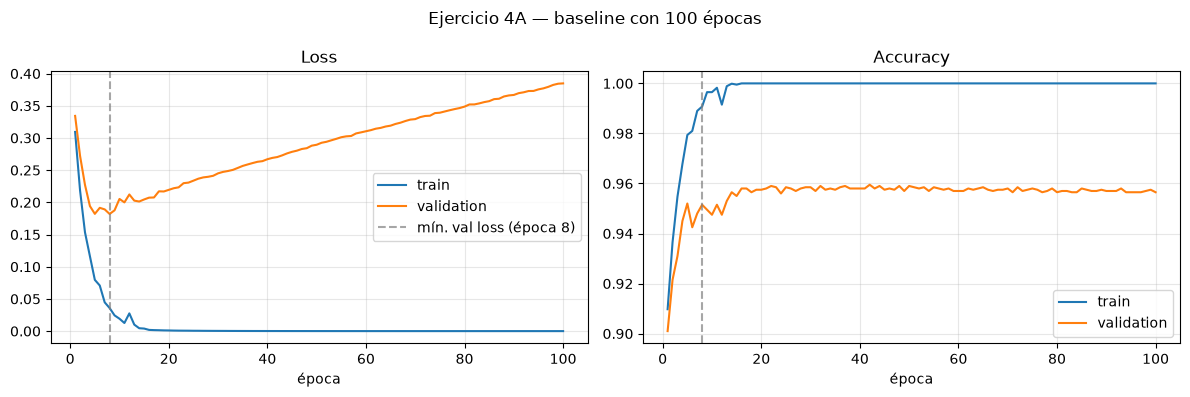

Accuracy final -> train: 1.0000 | val: 0.9565 | brecha (train - val): +4.35 pts
Loss final     -> train: 0.0000 | val: 0.3848
Mínimo de val loss: 0.1820 en la época 8 de 100


In [14]:
cfg = make_config(epochs=100)
model, hist = train_model(cfg, 'ex4_100ep', verbose=False)
plot_learning_curves(hist, 'Ejercicio 4A — baseline con 100 épocas')
print_summary(hist)

**Parte B — Tu cambio.** Mira la gráfica de arriba y la línea "Mínimo de val loss ... en la época X". Reentrena el mismo modelo **parando en esa época** cambiando el valor marcado con `TODO`.

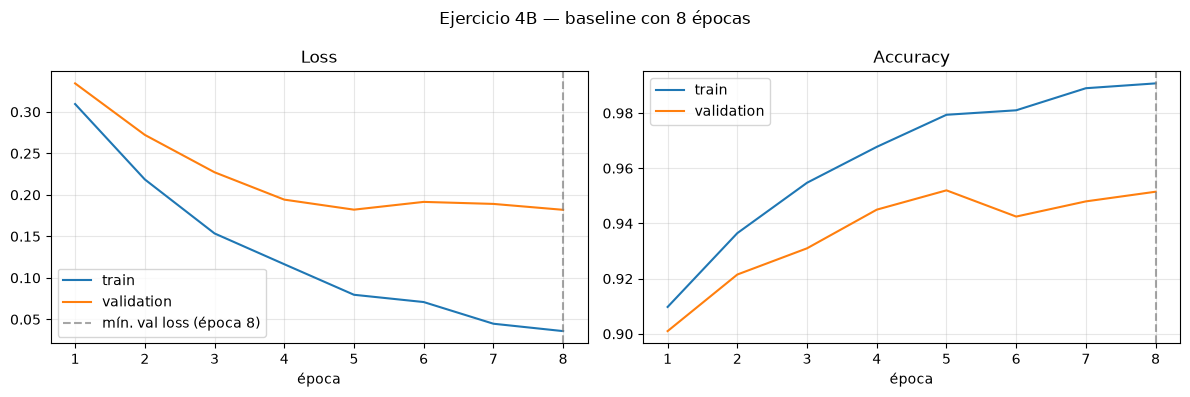

Accuracy final -> train: 0.9908 | val: 0.9515 | brecha (train - val): +3.93 pts
Loss final     -> train: 0.0358 | val: 0.1820
Mínimo de val loss: 0.1820 en la época 8 de 8


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex4_100ep,1.0000,0.9565,4.350,0.0000,0.3848,8,0.182
ex4_early,0.9908,0.9515,3.925,0.0358,0.1820,8,0.182


In [15]:
BEST_EPOCH = best_epoch(RESULTS['ex4_100ep']['history'])    # TODO: reemplaza por la época del mínimo de val loss que observaste en la Parte A

cfg = make_config(epochs=BEST_EPOCH)
model, hist = train_model(cfg, 'ex4_early', verbose=False)
plot_learning_curves(hist, f'Ejercicio 4B — baseline con {BEST_EPOCH} épocas')
print_summary(hist)
display(results_table('ex4_'))

**Preguntas:**
1. En la Parte A, ¿en qué época está el mínimo de la val loss? ¿Qué pasa con la val loss y la train loss después de esa época?
2. ¿Qué pasa con la **val accuracy** después de ese punto? ¿Se nota tanto como en la loss?
3. Compara los resultados finales de la Parte A y la Parte B (val loss y val accuracy). ¿Cuál es mejor? ¿Entrenar más épocas siempre ayuda?
4. ¿Qué ventaja tiene early stopping automático (con `patience`) frente a elegir la época a mano?

### 📝 Tus respuestas — Ejercicio 4

**Diagnóstico Parte A: Overfitting. Parte B: Modelo bueno.**

**100 épocas:** train acc **100.00 %**, val acc **95.65 %**, brecha **+4.35 pp**; train loss **0.0000**, val loss **0.3848**. Mínima val loss: **0.1820**, época **8**.

**Parada en la época elegida:** train acc **99.08 %**, val acc **95.15 %**, brecha **+3.93 pp**; train loss **0.0358**, val loss **0.1820**. Mínima val loss: **0.1820**, época **8**.

1. El mínimo de val loss está en la época 8. Después
   la train loss termina en 0.0000, pero la val loss
   sube desde 0.1820
   hasta 0.3848.
2. La val accuracy pasa de 95.15 %
   a 95.65 %. El cambio en accuracy no muestra
   el deterioro tan claramente como la loss.
3. La parada temprana deja val loss 0.1820 y
   val accuracy 95.15 %; con 100 épocas son
   0.3848 y 95.65 %.
   Prefiero la parada por su menor loss y menor brecha, aunque más épocas puedan
   acertar algunos casos adicionales.
4. Early stopping automático ahorra cómputo y adapta la parada a cada ejecución.
   Con patience tolera fluctuaciones; además debe conservar y restaurar los pesos
   del mejor punto, no simplemente los de la última época.

**Conclusión:** Entrenar más no siempre mejora la generalización.
Uso el mínimo de validación para decidir la parada, sin consultar el test.


---
## Ejercicio 5 — Dropout: un estudiante que no puede memorizar

**Contexto:** **Dropout** apaga aleatoriamente una fracción de las neuronas en cada paso de entrenamiento. Obliga a la red a no depender de neuronas concretas, y es como obligar al estudiante a estudiar sin poder apoyarse siempre en las mismas "pistas": le cuesta más memorizar.

**Parte A — Ya está dado.** Usamos el mismo modelo grande del Ejercicio 3, pero con `dropout=0.5`.

[ex5_dropout0.5] época   1/30 | train loss 0.2684 acc 0.9170 | val loss 0.3116 acc 0.9100


[ex5_dropout0.5] época   5/30 | train loss 0.0749 acc 0.9781 | val loss 0.1589 acc 0.9575


[ex5_dropout0.5] época  10/30 | train loss 0.0434 acc 0.9880 | val loss 0.1599 acc 0.9605


[ex5_dropout0.5] época  15/30 | train loss 0.0437 acc 0.9876 | val loss 0.2144 acc 0.9515


[ex5_dropout0.5] época  20/30 | train loss 0.0295 acc 0.9926 | val loss 0.2012 acc 0.9580


[ex5_dropout0.5] época  25/30 | train loss 0.0131 acc 0.9961 | val loss 0.2030 acc 0.9625


[ex5_dropout0.5] época  30/30 | train loss 0.0136 acc 0.9961 | val loss 0.2274 acc 0.9600
Parámetros: 2,913,290 | tiempo: 50.1 s


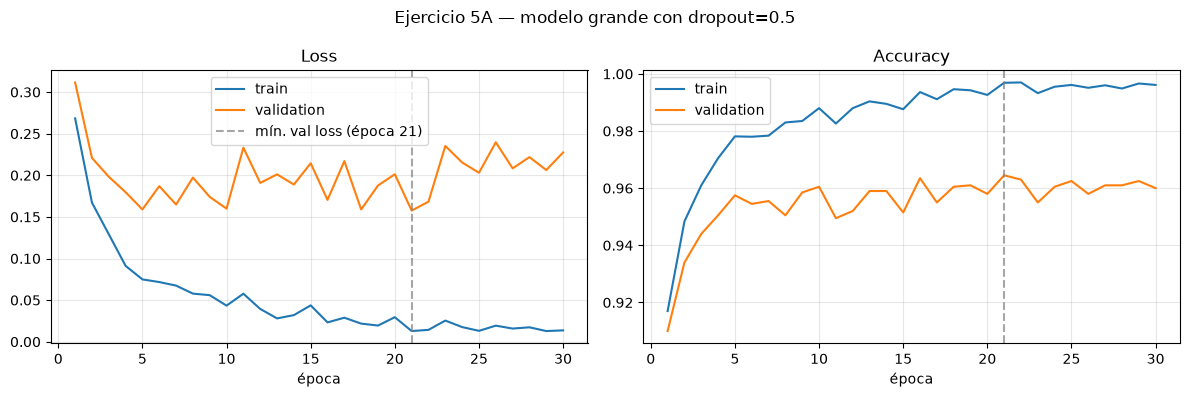

Accuracy final -> train: 0.9961 | val: 0.9600 | brecha (train - val): +3.61 pts
Loss final     -> train: 0.0136 | val: 0.2274
Mínimo de val loss: 0.1576 en la época 21 de 30


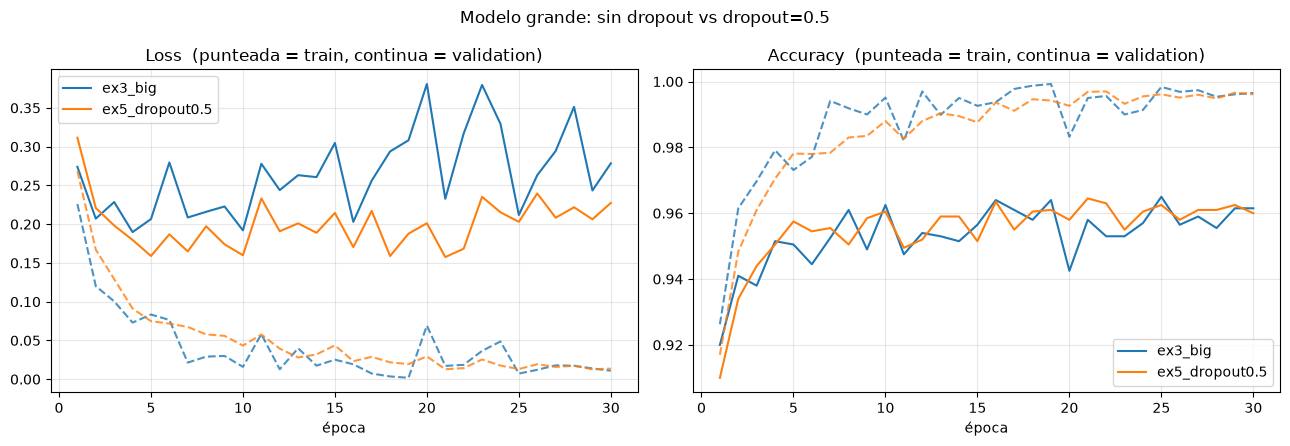

In [16]:
cfg = make_config(hidden_sizes=[1024, 1024, 1024], dropout=0.5)
model, hist = train_model(cfg, 'ex5_dropout0.5')
plot_learning_curves(hist, 'Ejercicio 5A — modelo grande con dropout=0.5')
print_summary(hist)

compare_runs(['ex3_big', 'ex5_dropout0.5'], 'Modelo grande: sin dropout vs dropout=0.5')

**Parte B — Tu cambio.** Prueba otro valor de dropout (por ejemplo `0.8`, que es muy agresivo, o `0.1`, que es suave). Cambia el valor marcado con `TODO`.

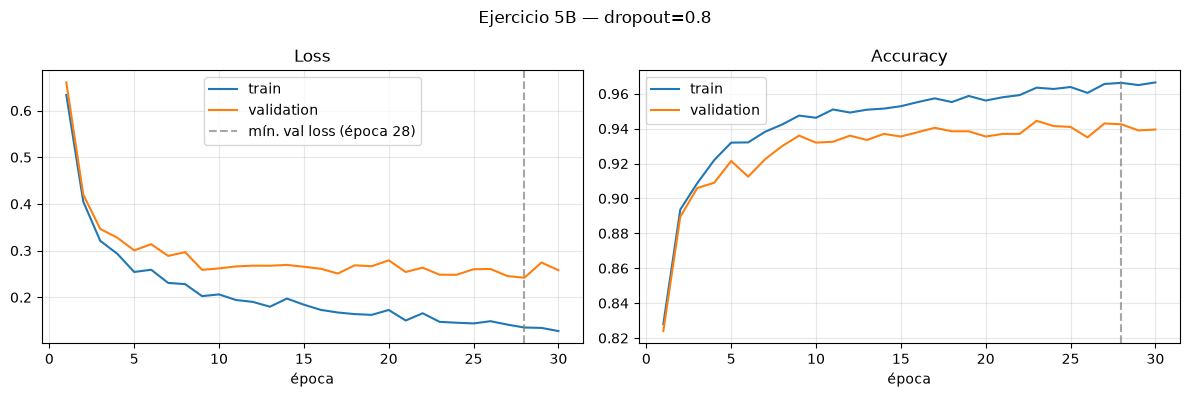

Accuracy final -> train: 0.9665 | val: 0.9395 | brecha (train - val): +2.70 pts
Loss final     -> train: 0.1277 | val: 0.2581
Mínimo de val loss: 0.2419 en la época 28 de 30


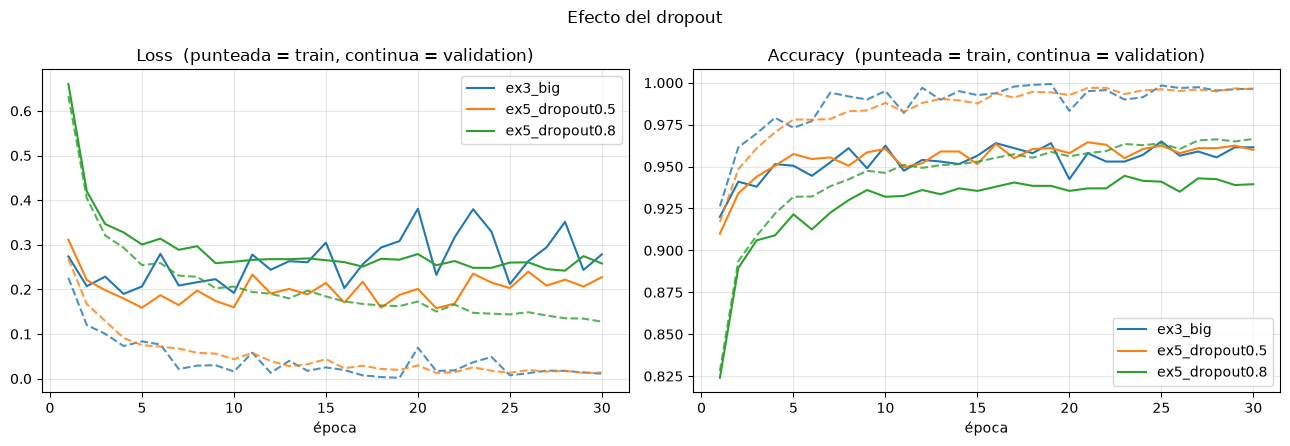

In [17]:
dropout_b = 0.8    # TODO: prueba otro valor entre 0.1 y 0.9

cfg = make_config(hidden_sizes=[1024, 1024, 1024], dropout=dropout_b)
model, hist = train_model(cfg, f'ex5_dropout{dropout_b}', verbose=False)
plot_learning_curves(hist, f'Ejercicio 5B — dropout={dropout_b}')
print_summary(hist)
compare_runs(['ex3_big', 'ex5_dropout0.5', f'ex5_dropout{dropout_b}'], 'Efecto del dropout')

**Preguntas:**
1. ¿Cómo cambió la brecha train-val al usar `dropout=0.5` respecto al Ejercicio 3?
2. ¿Cómo cambió el comportamiento de la val loss en las últimas épocas?
3. En la Parte B, ¿el valor que probaste mejora o empeora el resultado? ¿Puede una regularización **excesiva** producir el problema contrario (underfitting)? Justifica con tus números.
4. ¿Por qué usamos `model.eval()` al medir train y validation (es decir, por qué se desactiva el dropout)?

### 📝 Tus respuestas — Ejercicio 5

**Diagnóstico Parte A (0.5): Overfitting.**

**Diagnóstico Parte B (0.8): Modelo bueno, pero con menor ajuste y peor validación.**

**Dropout 0.5:** train acc **99.61 %**, val acc **96.00 %**, brecha **+3.61 pp**; train loss **0.0136**, val loss **0.2274**. Mínima val loss: **0.1576**, época **21**.

**Dropout 0.8:** train acc **96.65 %**, val acc **93.95 %**, brecha **+2.70 pp**; train loss **0.1277**, val loss **0.2581**. Mínima val loss: **0.2419**, época **28**.

1. Con 0.5, la brecha cambia de 3.50 a
   3.61 pp: no se reduce. La val loss sí mejora frente
   al modelo grande sin dropout, de 0.2784
   a 0.2274. No afirmo que dropout mejore
   automáticamente todas las métricas.
2. Con 0.5, la menor val loss es 0.1576
   en la época 21; después termina en
   0.2274. Todavía hay oscilación y sobreajuste.
3. Con 0.8 empeora la val accuracy a 93.95 %
   y la train accuracy baja a 96.65 %.
   La brecha menor no implica un modelo mejor: también cuesta más ajustar train.
   La regularización excesiva puede causar underfitting, pero aquí no observo
   un colapso claro: train todavía supera 96 %. Lo interpreto como menor ajuste
   respecto a 0.5, no como el subajuste severo del Ej. 2A.
4. Uso `model.eval()` para desactivar dropout y medir ambos conjuntos con la
   misma red completa, sin introducir apagados aleatorios en la evaluación.

**Conclusión:** Debo elegir dropout por la validación, no por reducir la brecha
aisladamente. En estos resultados 0.8 regulariza más, pero rinde peor que 0.5.


---
## Ejercicio 6 — Weight decay (regularización L2)

**Contexto:** **weight decay** penaliza los pesos grandes, empujando al modelo hacia soluciones más "simples". Con un valor adecuado reduce el overfitting, pero con un valor demasiado grande puede impedir que el modelo aprenda (¡y terminas en underfitting!).

**Qué hacer:** el bucle prueba tres valores de `weight_decay` sobre el baseline. Agrega **un valor más** a la lista (marcado con `TODO`) y ejecuta. Usamos Adam con penalización L2.

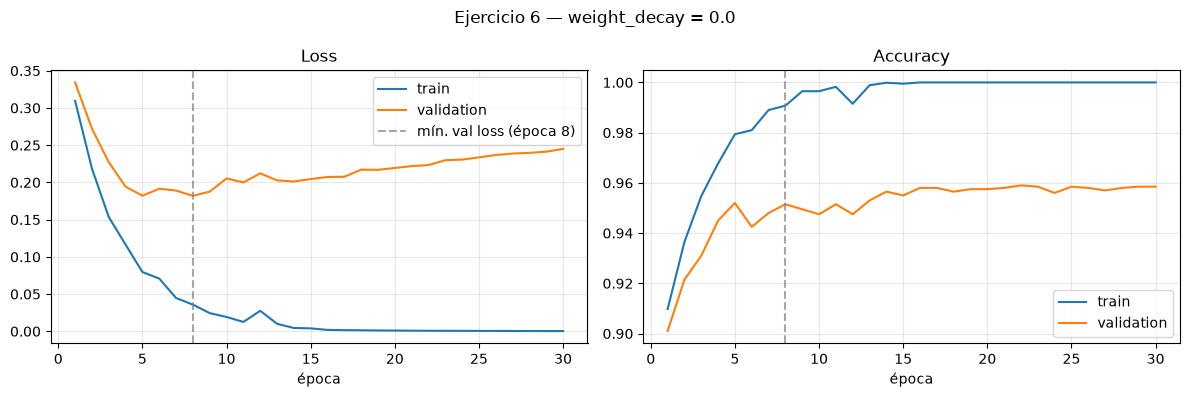

Accuracy final -> train: 1.0000 | val: 0.9585 | brecha (train - val): +4.15 pts
Loss final     -> train: 0.0003 | val: 0.2451
Mínimo de val loss: 0.1820 en la época 8 de 30
--------------------------------------------------------------------------------


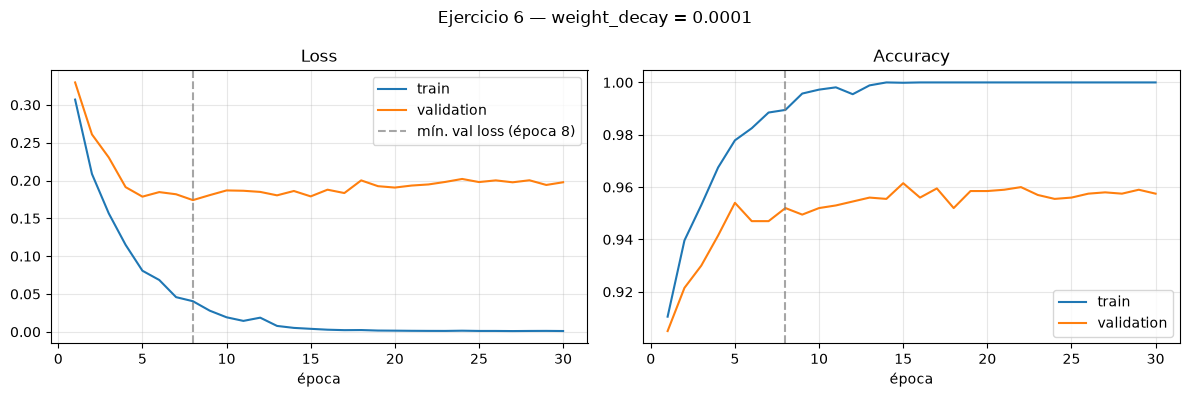

Accuracy final -> train: 1.0000 | val: 0.9575 | brecha (train - val): +4.25 pts
Loss final     -> train: 0.0010 | val: 0.1977
Mínimo de val loss: 0.1741 en la época 8 de 30
--------------------------------------------------------------------------------


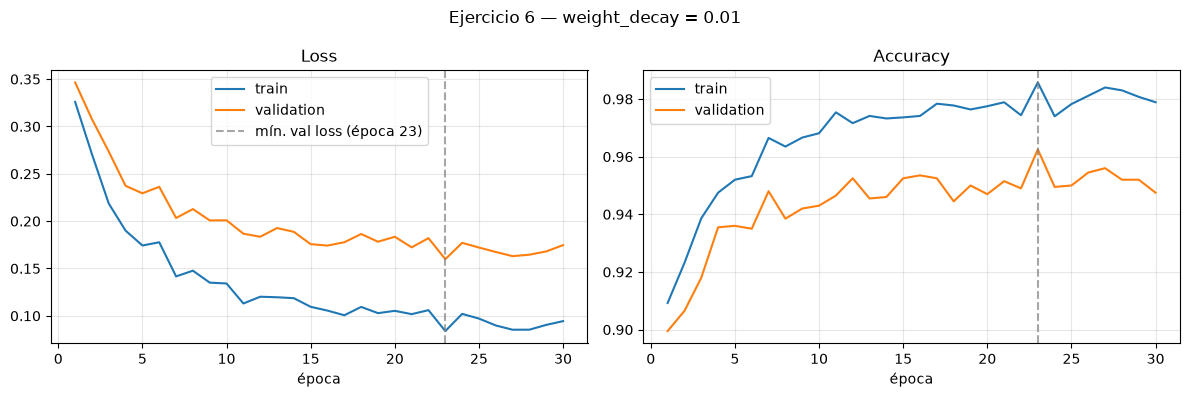

Accuracy final -> train: 0.9789 | val: 0.9475 | brecha (train - val): +3.14 pts
Loss final     -> train: 0.0944 | val: 0.1747
Mínimo de val loss: 0.1598 en la época 23 de 30
--------------------------------------------------------------------------------


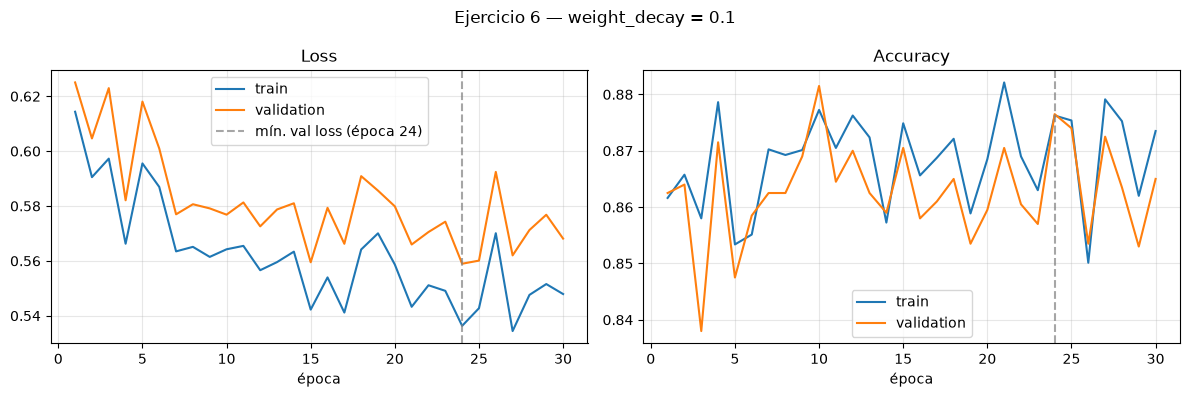

Accuracy final -> train: 0.8735 | val: 0.8650 | brecha (train - val): +0.85 pts
Loss final     -> train: 0.5479 | val: 0.5681
Mínimo de val loss: 0.5590 en la época 24 de 30
--------------------------------------------------------------------------------


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex6_wd0.0,1.0000,0.9585,4.1500,0.0003,0.2451,8,0.1820
ex6_wd0.0001,1.0000,0.9575,4.2500,0.0010,0.1977,8,0.1741
ex6_wd0.01,0.9789,0.9475,3.1375,0.0944,0.1747,23,0.1598
ex6_wd0.1,0.8735,0.8650,0.8500,0.5479,0.5681,24,0.5590


In [18]:
wd_values = [0.0, 1e-4, 1e-2, 1e-1]    # TODO: agrega un valor más (p. ej. 1e-1 o 1e-3)

for wd in wd_values:
    cfg = make_config(weight_decay=wd)
    model, hist = train_model(cfg, f'ex6_wd{wd}', verbose=False)
    plot_learning_curves(hist, f'Ejercicio 6 — weight_decay = {wd}')
    print_summary(hist)
    print('-' * 80)

display(results_table('ex6_'))

**Preguntas:**
1. ¿Qué diagnóstico le das a **cada** valor de `weight_decay` probado? (Úsalo para llenar la tabla.)
2. ¿Qué valor da la mejor val accuracy / menor val loss? ¿Se parece al modelo "bueno" de nuestra tabla de diagnóstico?
3. Explica por qué un `weight_decay` demasiado grande causa underfitting.
4. ¿Qué relación ves entre dropout (Ej. 5) y weight decay (Ej. 6)? ¿Los dos tratan el mismo problema?

### 📝 Tus respuestas — Ejercicio 6

**Diagnóstico por valor:**

| Configuración | Diagnóstico | Train acc | Val acc | Brecha (pp) | Train loss | Val loss |
|---|---|---:|---:|---:|---:|---:|
| 0.0 | Overfitting | 100.00 % | 95.85 % | +4.15 | 0.0003 | 0.2451 |
| 1e-4 | Overfitting | 100.00 % | 95.75 % | +4.25 | 0.0010 | 0.1977 |
| 1e-2 | Modelo bueno; brecha residual | 97.89 % | 94.75 % | +3.14 | 0.0944 | 0.1747 |
| 1e-1 | Underfitting | 87.35 % | 86.50 % | +0.85 | 0.5479 | 0.5681 |


1. Los diagnósticos y las métricas aparecen en la tabla. Agregué `weight_decay=0.1`.
2. La mejor val accuracy final corresponde a `ex6_wd0.0`:
   95.85 %. La menor val loss final corresponde a
   `ex6_wd0.01`: 0.1747.
   No son el mismo criterio: 0.01 ofrece menor loss y menor brecha, aunque
   sacrifica accuracy frente a 0.0. Es el ajuste más equilibrado de esta comparación,
   con una brecha residual de 3.14 pp.
3. Un valor demasiado grande penaliza tanto los pesos que dificulta representar
   los patrones. Con 0.1, incluso train baja a 87.35 %
   y su loss sube a 0.5479: una brecha pequeña
   también puede significar que ambos conjuntos rinden mal.
4. Dropout y weight decay buscan reducir el sobreajuste de forma distinta:
   uno apaga activaciones durante el aprendizaje y el otro penaliza los pesos.
   Ambos requieren ajustar su intensidad y pueden limitar demasiado el aprendizaje.

**Conclusión:** La regularización moderada mejora el equilibrio; la excesiva
produce subajuste. Distingo entre optimizar accuracy y reducir loss.


---
## Ejercicio 7 — Más datos: la mejor medicina contra el overfitting

**Contexto:** el estudiante B memoriza fácilmente cuando el libro de ejercicios es pequeño. Si el libro tiene miles de ejercicios, memorizar deja de ser viable y le conviene entender. Entrenaremos el baseline con **distintas cantidades de datos de entrenamiento** (la validación se mantiene fija en 2,000 muestras).

> 📝 Con menos datos hay menos pasos de gradiente por época; ten presente que eso también cambia el experimento.

**Qué hacer:** ejecuta la celda. Puedes modificar la lista `n_values` (`None` significa "usar todos los 8,000").

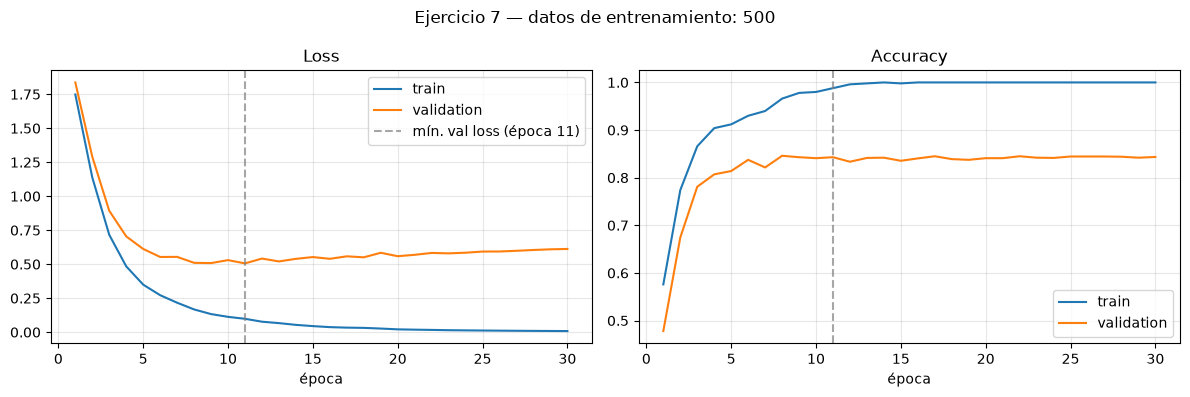

Accuracy final -> train: 1.0000 | val: 0.8435 | brecha (train - val): +15.65 pts
Loss final     -> train: 0.0081 | val: 0.6120
Mínimo de val loss: 0.5059 en la época 11 de 30
--------------------------------------------------------------------------------


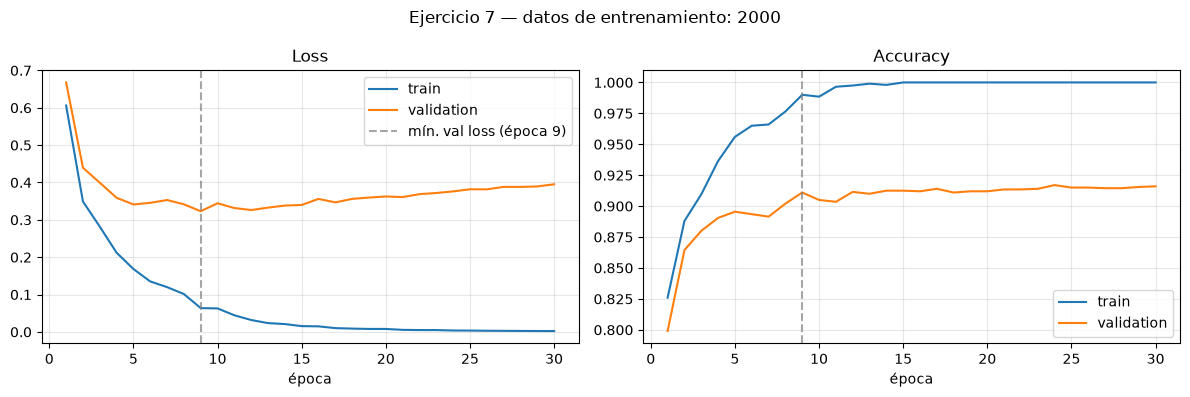

Accuracy final -> train: 1.0000 | val: 0.9160 | brecha (train - val): +8.40 pts
Loss final     -> train: 0.0023 | val: 0.3952
Mínimo de val loss: 0.3231 en la época 9 de 30
--------------------------------------------------------------------------------


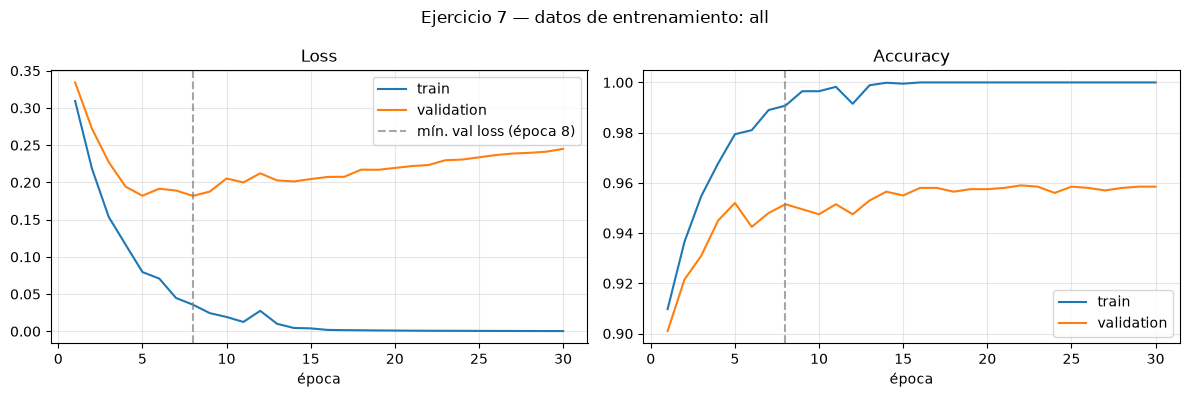

Accuracy final -> train: 1.0000 | val: 0.9585 | brecha (train - val): +4.15 pts
Loss final     -> train: 0.0003 | val: 0.2451
Mínimo de val loss: 0.1820 en la época 8 de 30
--------------------------------------------------------------------------------


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex7_n500,1.0,0.8435,15.65,0.0081,0.6120,11,0.5059
ex7_n2000,1.0,0.9160,8.40,0.0023,0.3952,9,0.3231
ex7_nall,1.0,0.9585,4.15,0.0003,0.2451,8,0.1820


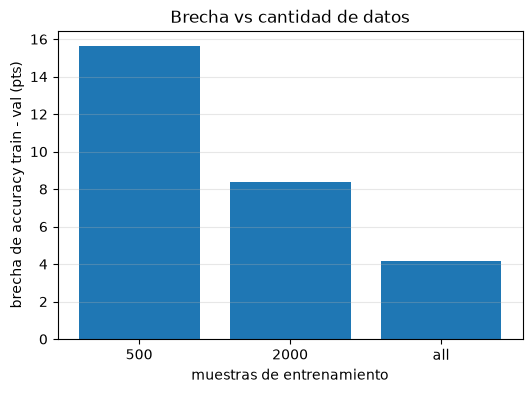

In [19]:
n_values = [500, 2000, None]    # TODO (opcional): prueba otros tamaños (cada valor debe ser >= 64)

labels = ['all' if n is None else n for n in n_values]
for n, label in zip(n_values, labels):
    cfg = make_config(n_train=n)
    model, hist = train_model(cfg, f'ex7_n{label}', verbose=False)
    plot_learning_curves(hist, f'Ejercicio 7 — datos de entrenamiento: {label}')
    print_summary(hist)
    print('-' * 80)

names = [f'ex7_n{l}' for l in labels]
tab = results_table().loc[names]
display(tab)

plt.figure(figsize=(6, 4))
plt.bar([str(l) for l in labels], tab['brecha_acc_pts'])
plt.xlabel('muestras de entrenamiento')
plt.ylabel('brecha de accuracy train - val (pts)')
plt.title('Brecha vs cantidad de datos')
plt.grid(alpha=0.3, axis='y')
plt.show()

**Preguntas:**
1. ¿Cómo cambia la brecha train-val al aumentar los datos de entrenamiento?
2. ¿Cómo cambia la val accuracy? ¿Y la val loss?
3. ¿Cuál es el diagnóstico del experimento con **menos** datos? ¿Y del que usa **todos**?
4. En proyectos reales, ¿siempre es posible conseguir más datos? Menciona una alternativa para "simular" más datos (pista: *data augmentation*).

### 📝 Tus respuestas — Ejercicio 7

**Diagnóstico por experimento:**

| Configuración | Diagnóstico | Train acc | Val acc | Brecha (pp) | Train loss | Val loss |
|---|---|---:|---:|---:|---:|---:|
| 500 | Overfitting | 100.00 % | 84.35 % | +15.65 | 0.0081 | 0.6120 |
| 2,000 | Overfitting | 100.00 % | 91.60 % | +8.40 | 0.0023 | 0.3952 |
| 8,000 | Overfitting más leve | 100.00 % | 95.85 % | +4.15 | 0.0003 | 0.2451 |


1. La brecha disminuye de 15.65 a 8.40
   y luego a 4.15 pp al aumentar las muestras.
2. La val accuracy pasa de 84.35 % a
   91.60 % y 95.85 %;
   la val loss baja de 0.6120 a
   0.3952 y 0.2451.
3. Con 500 datos hay sobreajuste claro: train llega al 100 % pero validation
   queda muy atrás. Con 8,000 mejora mucho, aunque train sigue en 100 % y la
   val loss termina por encima de su mínimo: el problema se reduce, no desaparece.
4. Más datos pueden ser costosos o difíciles de etiquetar. Usaría data augmentation,
   por ejemplo pequeñas traslaciones o rotaciones que conserven el dígito.
   No transformaría la validación ni el test como si fueran nuevas muestras de train.

**Conclusión:** Más datos mejora la generalización en esta prueba.
También aumenta los pasos de optimización por época; no aíslo exclusivamente el
efecto de la cantidad de muestras manteniendo fijo el número de actualizaciones.


---
## Ejercicio 8 — Learning rate: cuando el underfitting no es culpa de la capacidad

**Contexto:** el learning rate controla qué tan grandes son los pasos de optimización. Si es **muy pequeño**, el modelo aprende tan despacio que en 30 épocas no llega a ajustarse (underfitting por entrenamiento insuficiente). Si es **muy grande**, los pasos son tan bruscos que el entrenamiento se vuelve inestable y tampoco aprende.

> 📝 En ambos casos el modelo ve **errores altos también en train**, por lo que lo clasificamos como *underfitting*, aunque la **causa** sea la optimización y no la falta de capacidad.

**Parte A — Ya está dado.** Probamos tres valores de learning rate sobre el baseline.

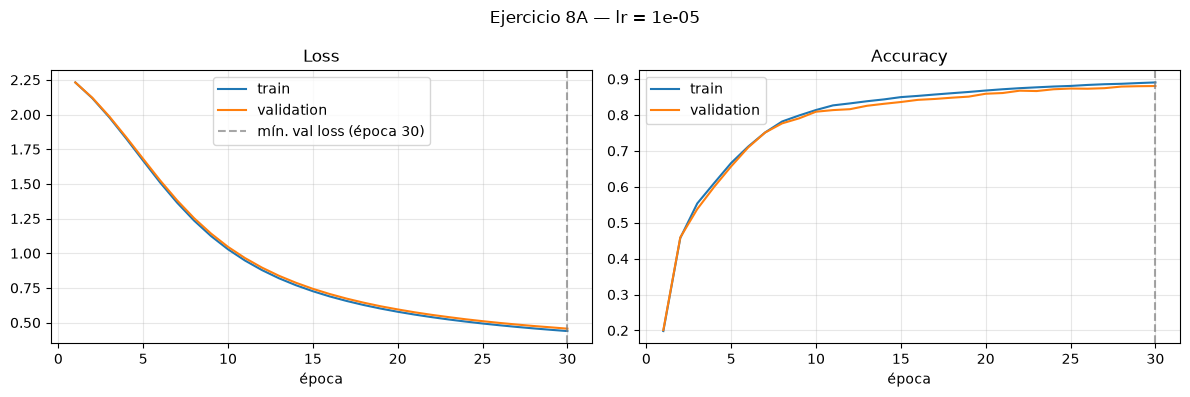

Accuracy final -> train: 0.8905 | val: 0.8805 | brecha (train - val): +1.00 pts
Loss final     -> train: 0.4391 | val: 0.4565
Mínimo de val loss: 0.4565 en la época 30 de 30
--------------------------------------------------------------------------------


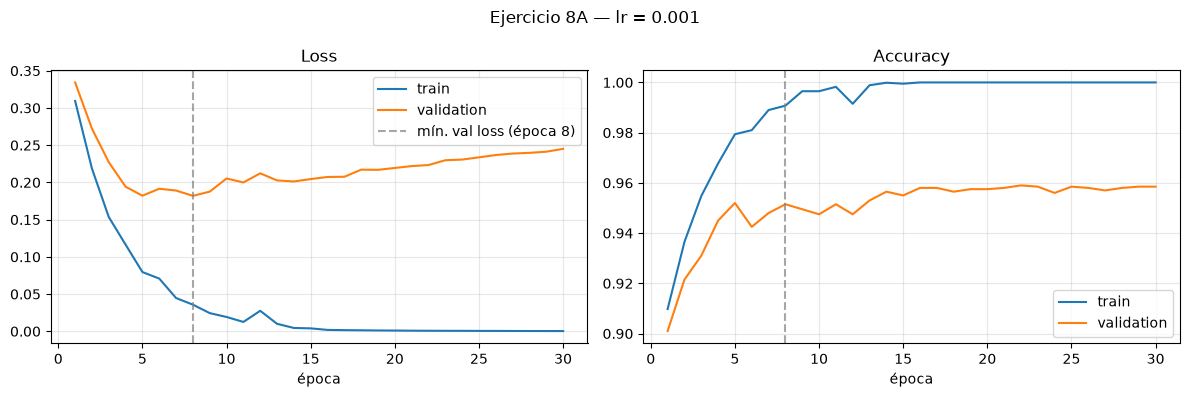

Accuracy final -> train: 1.0000 | val: 0.9585 | brecha (train - val): +4.15 pts
Loss final     -> train: 0.0003 | val: 0.2451
Mínimo de val loss: 0.1820 en la época 8 de 30
--------------------------------------------------------------------------------


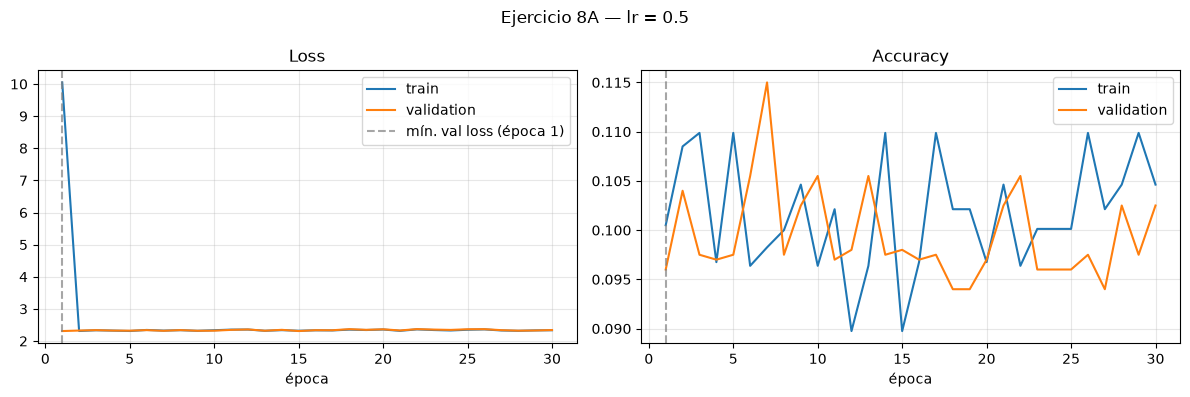

Accuracy final -> train: 0.1046 | val: 0.1025 | brecha (train - val): +0.21 pts
Loss final     -> train: 2.3358 | val: 2.3416
Mínimo de val loss: 2.3101 en la época 1 de 30
--------------------------------------------------------------------------------


In [20]:
lr_values = [1e-5, 1e-3, 5e-1]

for lr in lr_values:
    cfg = make_config(lr=lr)
    model, hist = train_model(cfg, f'ex8_lr{lr}', verbose=False)
    plot_learning_curves(hist, f'Ejercicio 8A — lr = {lr}')
    print_summary(hist)
    print('-' * 80)

**Parte B — Tu cambio.** Con `lr = 1e-5` el modelo parece que "todavía no termina de aprender". ¿Se arregla entrenando más épocas? Cambia el número de épocas marcado con `TODO`.

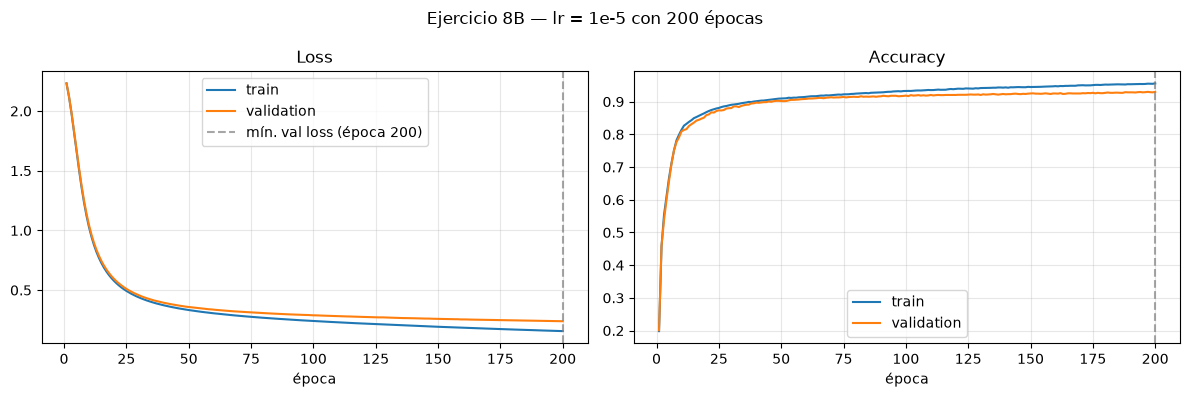

Accuracy final -> train: 0.9559 | val: 0.9300 | brecha (train - val): +2.59 pts
Loss final     -> train: 0.1568 | val: 0.2395
Mínimo de val loss: 0.2395 en la época 200 de 200


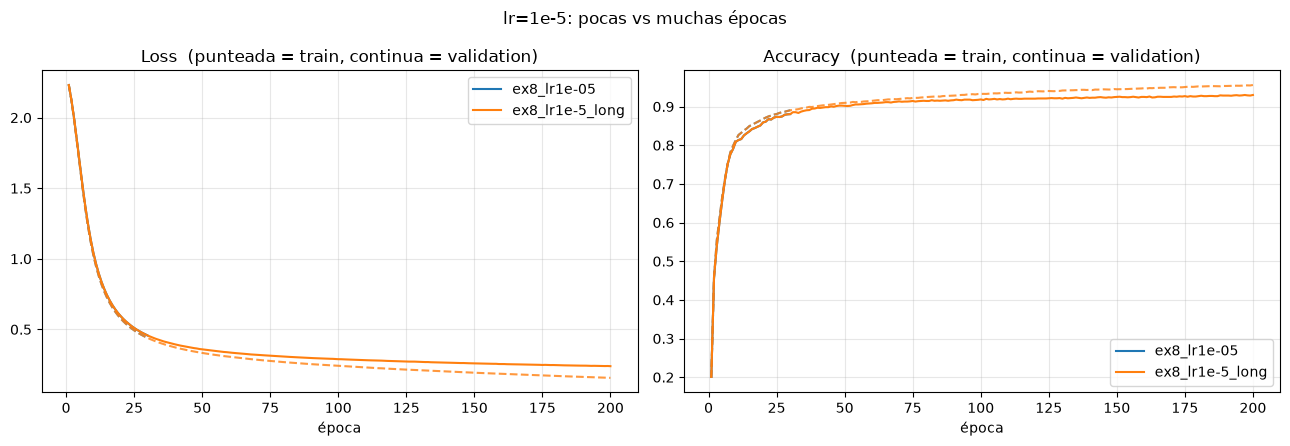

In [21]:
EPOCHS_B = 200    # TODO: prueba con más épocas (p. ej. 100 o 200)

cfg = make_config(lr=1e-5, epochs=EPOCHS_B)
model, hist = train_model(cfg, 'ex8_lr1e-5_long', verbose=False)
plot_learning_curves(hist, f'Ejercicio 8B — lr = 1e-5 con {EPOCHS_B} épocas')
print_summary(hist)
compare_runs(['ex8_lr1e-05', 'ex8_lr1e-5_long'], 'lr=1e-5: pocas vs muchas épocas')

**Preguntas:**
1. ¿Qué diagnóstico le das a cada learning rate de la Parte A? Cita train acc y val acc.
2. En `lr = 1e-5`, ¿las curvas ya "se aplanaron" o todavía estaban mejorando al terminar? ¿Qué te dice eso?
3. En `lr = 5e-1`, ¿qué comportamiento ves en las curvas? ¿Se parece a algún caso de la tabla de diagnóstico? ¿En qué se diferencia la **causa**?
4. En la Parte B, ¿entrenar más épocas resolvió el problema? ¿Qué otra solución sería más eficiente?

### 📝 Tus respuestas — Ejercicio 8

**Diagnóstico por learning rate:**

| Configuración | Diagnóstico | Train acc | Val acc | Brecha (pp) | Train loss | Val loss |
|---|---|---:|---:|---:|---:|---:|
| 1e-5, 30 épocas | Underfitting | 89.05 % | 88.05 % | +1.00 | 0.4391 | 0.4565 |
| 1e-3, 30 épocas | Overfitting | 100.00 % | 95.85 % | +4.15 | 0.0003 | 0.2451 |
| 0.5, 30 épocas | Underfitting por mala optimización | 10.46 % | 10.25 % | +0.21 | 2.3358 | 2.3416 |
| 1e-5, 200 épocas | Modelo bueno; entrenamiento lento | 95.59 % | 93.00 % | +2.59 | 0.1568 | 0.2395 |


1. La tabla muestra train/validation, brecha y losses para cada caso.
2. Con 1e-5 las curvas siguen mejorando: el mínimo de val loss se da en la última
   época de las 30 (0.4565). Los pasos son tan pequeños
   que todavía no termina de aprender, pese a tener la capacidad del baseline.
3. Con 0.5 aparecen oscilaciones y rendimiento cercano al azar:
   10.46 % en train y
   10.25 % en validation. Se parece al underfitting
   porque ambos rinden mal, pero la causa es la optimización, no pocas neuronas.
4. Con 200 épocas, train llega a 95.59 %
   y validation a 93.00 %, con val loss
   0.2395. Mejora mucho el subajuste inicial,
   aunque no significa que haya convergido por completo. Sería más eficiente
   aumentar moderadamente el learning rate y elegir la parada con validation.

**Conclusión:** Un mal resultado en train también puede venir del learning rate.
Más épocas ayuda cuando los pasos son demasiado pequeños; no arregla por sí sola
un learning rate excesivo.


---
## Ejercicio 9 — Batch Normalization y función de activación

**Contexto:** **Batch Normalization** normaliza las activaciones de cada capa y suele estabilizar y acelerar el entrenamiento; como efecto secundario, puede regularizar un poco. La **función de activación** (ReLU, tanh, ...) cambia cómo la red representa la información. Usaremos el mismo baseline del Ejercicio 1 para que la comparación sea limpia.

**Parte A — Batch Norm:** ya está dado.

[ex9a_batchnorm] época   1/30 | train loss 0.2880 acc 0.9395 | val loss 0.3217 acc 0.9270


[ex9a_batchnorm] época   5/30 | train loss 0.0281 acc 0.9965 | val loss 0.1457 acc 0.9610


[ex9a_batchnorm] época  10/30 | train loss 0.0058 acc 0.9998 | val loss 0.1441 acc 0.9595


[ex9a_batchnorm] época  15/30 | train loss 0.0063 acc 0.9990 | val loss 0.1619 acc 0.9560


[ex9a_batchnorm] época  20/30 | train loss 0.0051 acc 0.9989 | val loss 0.1656 acc 0.9535


[ex9a_batchnorm] época  25/30 | train loss 0.0004 acc 1.0000 | val loss 0.1492 acc 0.9625


[ex9a_batchnorm] época  30/30 | train loss 0.0040 acc 0.9990 | val loss 0.2138 acc 0.9510
Parámetros: 109,770 | tiempo: 5.7 s


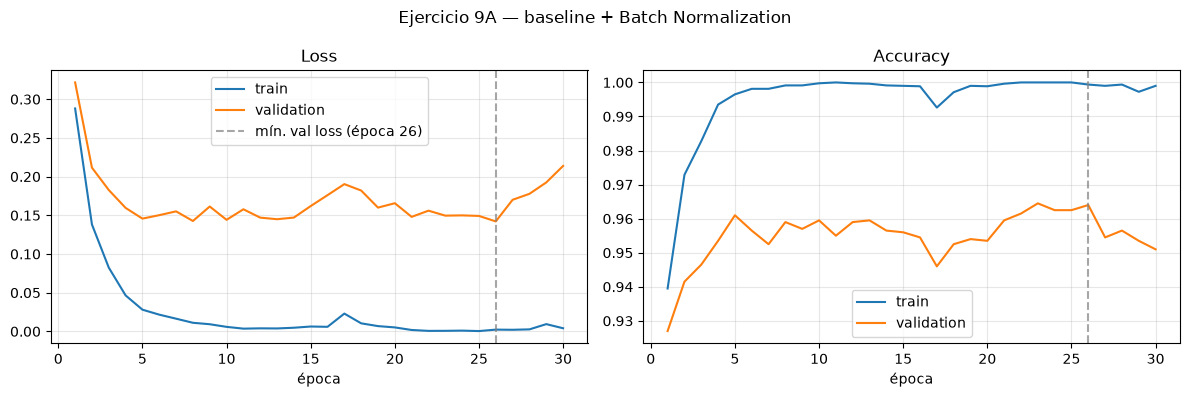

Accuracy final -> train: 0.9990 | val: 0.9510 | brecha (train - val): +4.80 pts
Loss final     -> train: 0.0040 | val: 0.2138
Mínimo de val loss: 0.1421 en la época 26 de 30


In [22]:
cfg = make_config(batch_norm=True)
model, hist = train_model(cfg, 'ex9a_batchnorm')
plot_learning_curves(hist, 'Ejercicio 9A — baseline + Batch Normalization')
print_summary(hist)

**Parte B — Activación.** Cambia la activación de ReLU a otra. Está puesta `'tanh'`; en la celda marcada con `TODO` puedes probar `'leaky_relu'` o `'gelu'` si quieres una comparación extra.

[ex9b_tanh] época   1/30 | train loss 0.3038 acc 0.9200 | val loss 0.3282 acc 0.9125


[ex9b_tanh] época   5/30 | train loss 0.0693 acc 0.9841 | val loss 0.1822 acc 0.9495


[ex9b_tanh] época  10/30 | train loss 0.0093 acc 0.9994 | val loss 0.1783 acc 0.9550


[ex9b_tanh] época  15/30 | train loss 0.0026 acc 1.0000 | val loss 0.1828 acc 0.9555


[ex9b_tanh] época  20/30 | train loss 0.0013 acc 1.0000 | val loss 0.1906 acc 0.9550


[ex9b_tanh] época  25/30 | train loss 0.0007 acc 1.0000 | val loss 0.1968 acc 0.9565


[ex9b_tanh] época  30/30 | train loss 0.0004 acc 1.0000 | val loss 0.2030 acc 0.9570
Parámetros: 109,386 | tiempo: 4.3 s


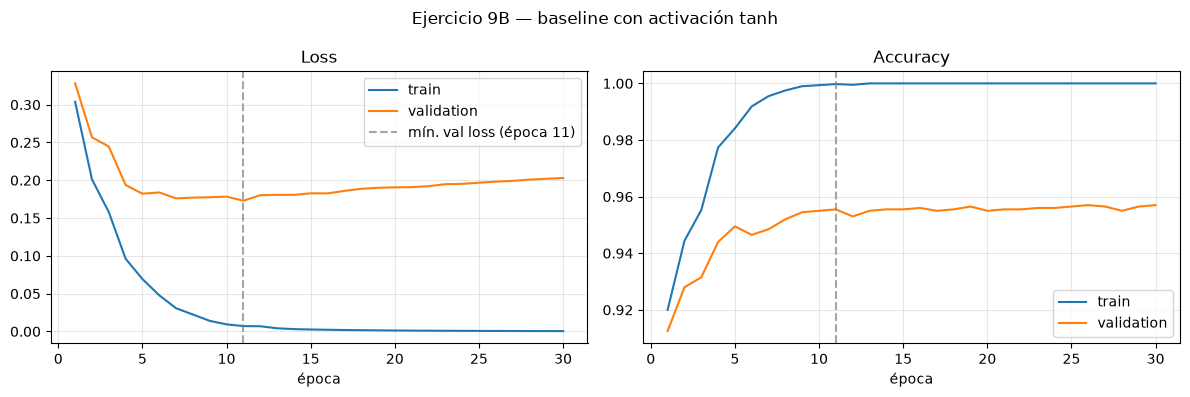

Accuracy final -> train: 1.0000 | val: 0.9570 | brecha (train - val): +4.30 pts
Loss final     -> train: 0.0004 | val: 0.2030
Mínimo de val loss: 0.1729 en la época 11 de 30


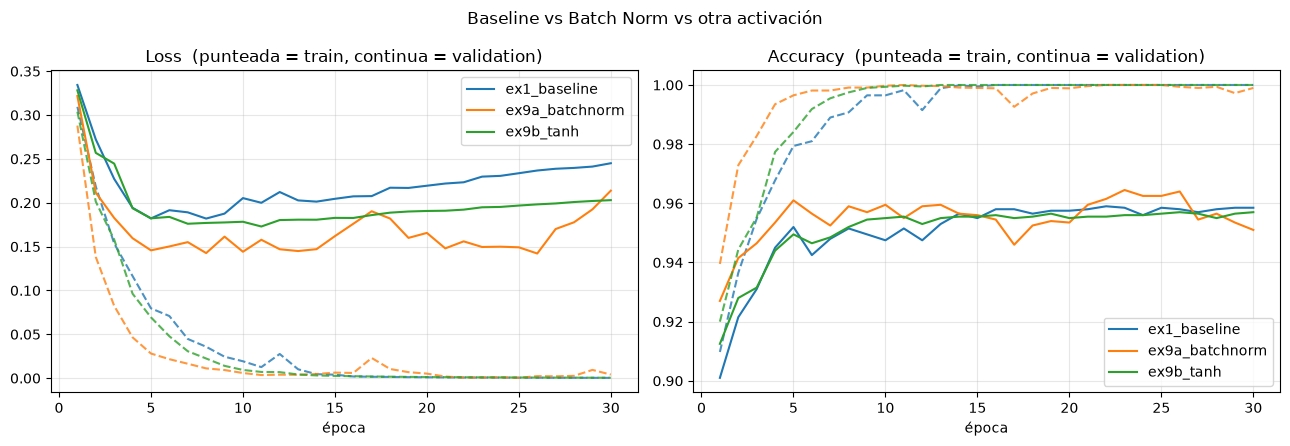

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex9a_batchnorm,0.999,0.951,4.8,0.0040,0.2138,26,0.1421
ex9b_tanh,1.000,0.957,4.3,0.0004,0.2030,11,0.1729


In [23]:
activation_b = 'tanh'    # TODO (opcional): prueba 'leaky_relu' o 'gelu'

cfg = make_config(activation=activation_b)
model, hist = train_model(cfg, f'ex9b_{activation_b}')
plot_learning_curves(hist, f'Ejercicio 9B — baseline con activación {activation_b}')
print_summary(hist)

compare_runs(['ex1_baseline', 'ex9a_batchnorm', f'ex9b_{activation_b}'],
             'Baseline vs Batch Norm vs otra activación')
display(results_table('ex9'))

**Preguntas:**
1. ¿Batch Norm cambió la velocidad de convergencia (qué tan rápido baja la loss en las primeras épocas)?
2. ¿Batch Norm redujo, mantuvo o aumentó la brecha train-val respecto al baseline? ¿Podemos decir que "regulariza"?
3. ¿La activación que probaste cambia el diagnóstico respecto al baseline? ¿Qué diferencias notas?
4. Si tuvieras que elegir entre Batch Norm y Dropout para reducir overfitting, ¿qué evidencia de esta tarea usarías?

### 📝 Tus respuestas — Ejercicio 9

**Diagnóstico Parte A (Batch Norm): Overfitting.**

**Diagnóstico Parte B (tanh): Overfitting.**

**Batch Norm:** train acc **99.90 %**, val acc **95.10 %**, brecha **+4.80 pp**; train loss **0.0040**, val loss **0.2138**. Mínima val loss: **0.1421**, época **26**.

**tanh:** train acc **100.00 %**, val acc **95.70 %**, brecha **+4.30 pp**; train loss **0.0004**, val loss **0.2030**. Mínima val loss: **0.1729**, época **11**.

1. Sí acelera la bajada inicial: en la época 5 la train loss es
   0.0281, frente a
   0.0796 del baseline; las val losses son
   0.1457 y 0.1821.
2. La brecha final aumenta de 4.15 a
   4.80 pp. Batch Norm puede tener efectos de
   regularización, pero aquí no demuestra reducir la brecha ni eliminar sobreajuste.
3. Con tanh se mantiene el diagnóstico: train llega a
   100.00 %, validation a
   95.70 % y la val loss termina por encima
   del mínimo de la época 11. Cambia la curva y reduce
   la loss final frente al baseline, sin resolver la separación entre conjuntos.
4. Consideraría dropout como regularización explícita, pero usaría los números:
   0.5 reduce la loss del modelo grande sin reducir su brecha; 0.8 deja
   2.70 pp de brecha a costa de menor accuracy.
   Batch Norm acelera el aprendizaje, pero termina con 4.80 pp.
   Como los ejercicios usan arquitecturas distintas, no concluyo que una técnica
   sea superior en general sin compararlas sobre la misma red.

**Conclusión:** Acelerar la convergencia no equivale a evitar el sobreajuste.
Debo revisar la curva completa y combinar una parada adecuada con regularización.


---
## Ejercicio 10 — Diseña tu modelo final (y por fin usa el test)

**Contexto:** ahora aplicas todo lo aprendido. Tu objetivo es lograr un modelo con **buen ajuste**: alta accuracy en validation y brecha train-val pequeña.

**Reglas:**
1. Modifica los hiperparámetros marcados con `TODO` en `FINAL_CONFIG` (puedes cambiar cualquiera).
2. Tienes **máximo 5 intentos**. Sube `ATTEMPT` en 1 cada vez, y anota en la tabla de abajo qué cambiaste y por qué.
3. **Toma tus decisiones solo con train y validation.** El test no se toca hasta el final.
4. Cuando ya tengas tu modelo final, ejecuta **una sola vez** la celda de test.

[ex10_intento1] época   1/8 | train loss 0.2730 acc 0.9190 | val loss 0.3002 acc 0.9095


[ex10_intento1] época   5/8 | train loss 0.0716 acc 0.9798 | val loss 0.1745 acc 0.9465


[ex10_intento1] época   8/8 | train loss 0.0276 acc 0.9931 | val loss 0.1533 acc 0.9545
Parámetros: 235,146 | tiempo: 1.7 s


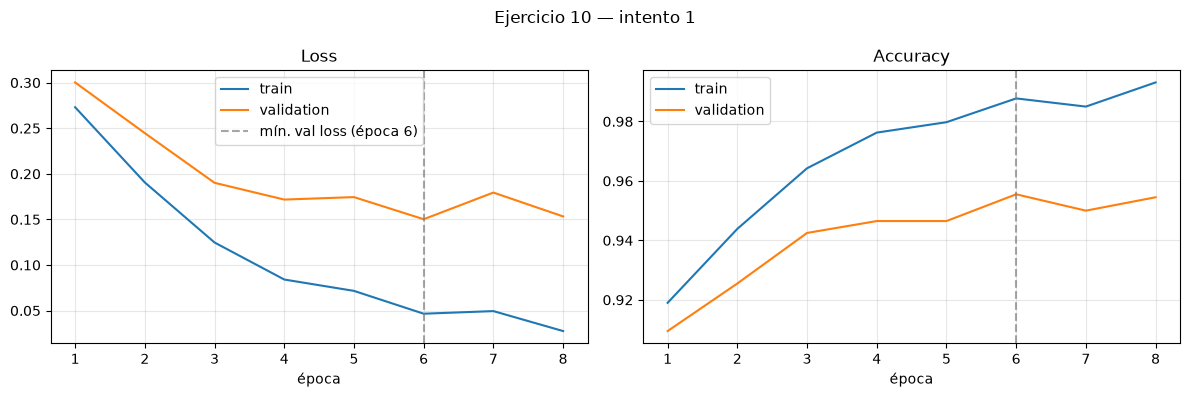

Accuracy final -> train: 0.9931 | val: 0.9545 | brecha (train - val): +3.86 pts
Loss final     -> train: 0.0276 | val: 0.1533
Mínimo de val loss: 0.1502 en la época 6 de 8


[ex10_intento2] época   1/16 | train loss 0.2730 acc 0.9190 | val loss 0.3002 acc 0.9095


[ex10_intento2] época   5/16 | train loss 0.0716 acc 0.9798 | val loss 0.1745 acc 0.9465


[ex10_intento2] época  10/16 | train loss 0.0283 acc 0.9905 | val loss 0.1929 acc 0.9505


[ex10_intento2] época  15/16 | train loss 0.0069 acc 0.9990 | val loss 0.1660 acc 0.9600
[ex10_intento2] época  16/16 | train loss 0.0080 acc 0.9984 | val loss 0.1854 acc 0.9600
Parámetros: 235,146 | tiempo: 3.6 s


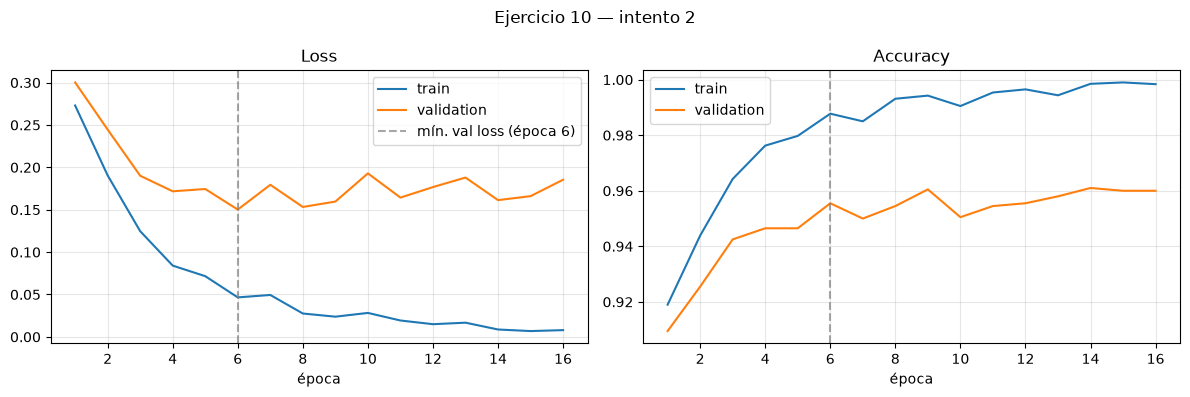

Accuracy final -> train: 0.9984 | val: 0.9600 | brecha (train - val): +3.84 pts
Loss final     -> train: 0.0080 | val: 0.1854
Mínimo de val loss: 0.1502 en la época 6 de 16


[ex10_intento3] época   1/16 | train loss 0.3140 acc 0.9074 | val loss 0.3378 acc 0.9005


[ex10_intento3] época   5/16 | train loss 0.1034 acc 0.9679 | val loss 0.2004 acc 0.9390


[ex10_intento3] época  10/16 | train loss 0.0411 acc 0.9879 | val loss 0.1676 acc 0.9525


[ex10_intento3] época  15/16 | train loss 0.0186 acc 0.9961 | val loss 0.1672 acc 0.9590
[ex10_intento3] época  16/16 | train loss 0.0230 acc 0.9939 | val loss 0.1781 acc 0.9560
Parámetros: 235,146 | tiempo: 3.5 s


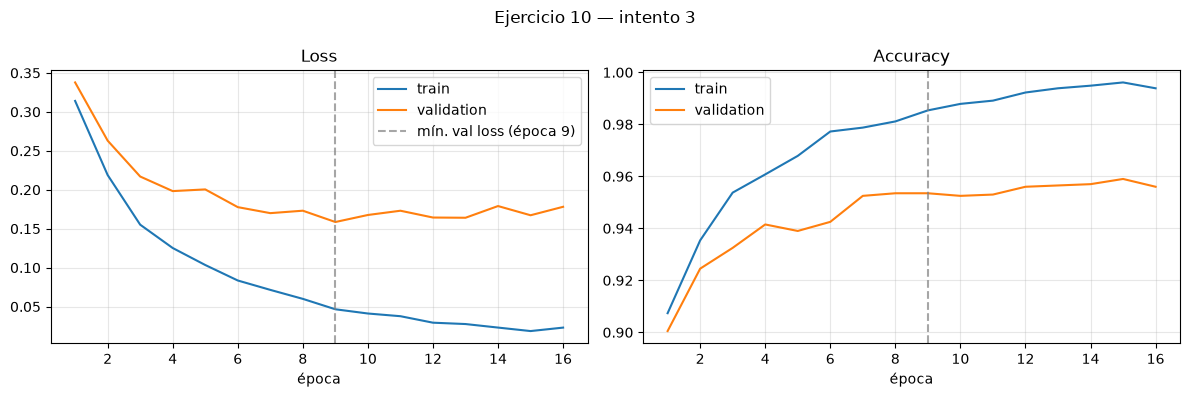

Accuracy final -> train: 0.9939 | val: 0.9560 | brecha (train - val): +3.79 pts
Loss final     -> train: 0.0230 | val: 0.1781
Mínimo de val loss: 0.1586 en la época 9 de 16
Intento seleccionado antes del test: 1
Configuración seleccionada: {'hidden_sizes': [256, 128], 'activation': 'relu', 'dropout': 0.2, 'batch_norm': False, 'optimizer': 'adam', 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'epochs': 8, 'n_train': None}


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex10_intento1,0.9931,0.9545,3.8625,0.0276,0.1533,6,0.1502
ex10_intento2,0.9984,0.9600,3.8375,0.0080,0.1854,6,0.1502
ex10_intento3,0.9939,0.9560,3.7875,0.0230,0.1781,9,0.1586


In [24]:
# Tres intentos definidos antes de consultar el test; máximo permitido: cinco.
# Uso la época sugerida por el Ej. 4 como presupuesto inicial y luego
# pruebo si una regularización moderada permite entrenar más tiempo.
attempt_configs = [
    make_config(hidden_sizes=[256, 128], dropout=0.2, weight_decay=1e-4,
                epochs=BEST_EPOCH),
    make_config(hidden_sizes=[256, 128], dropout=0.2, weight_decay=1e-4,
                epochs=max(10, 2 * BEST_EPOCH)),
    make_config(hidden_sizes=[256, 128], dropout=0.4, weight_decay=1e-4,
                epochs=max(10, 2 * BEST_EPOCH)),
]
attempt_models = {}
for ATTEMPT, FINAL_CONFIG in enumerate(attempt_configs, start=1):
    candidate, candidate_hist = train_model(FINAL_CONFIG, f'ex10_intento{ATTEMPT}')
    attempt_models[ATTEMPT] = candidate
    plot_learning_curves(candidate_hist, f'Ejercicio 10 — intento {ATTEMPT}')
    print_summary(candidate_hist)

# Selección exclusivamente por la loss final de validación; desempate por accuracy.
selected_attempt = min(attempt_models, key=lambda a: (
    RESULTS[f'ex10_intento{a}']['history']['val_loss'][-1],
    -RESULTS[f'ex10_intento{a}']['history']['val_acc'][-1],
))
ATTEMPT = selected_attempt
FINAL_CONFIG = RESULTS[f'ex10_intento{ATTEMPT}']['config']
final_model = attempt_models[ATTEMPT]
final_hist = RESULTS[f'ex10_intento{ATTEMPT}']['history']
print('Intento seleccionado antes del test:', ATTEMPT)
print('Configuración seleccionada:', FINAL_CONFIG)
display(results_table('ex10_'))


### 📝 Bitácora de intentos — Ejercicio 10

| Intento | Qué cambié y por qué | Train acc | Val acc | Brecha (pp) | Diagnóstico |
|---|---|---:|---:|---:|---|
| 1 | Red [256,128], dropout 0.2 y L2 1e-4; paro en 8 épocas según el Ej. 4. | 99.31 % | 95.45 % | +3.86 | Modelo bueno; brecha residual |
| 2 | Mantengo lo anterior y extiendo a 16 épocas para comprobar si regularizar permite seguir aprendiendo. | 99.84 % | 96.00 % | +3.84 | Overfitting leve |
| 3 | Mantengo 16 épocas y aumento dropout a 0.4 para intentar contener el sobreajuste. | 99.39 % | 95.60 % | +3.79 | Overfitting leve |


Realicé **3 de los 5 intentos permitidos**. No realicé los intentos 4 y 5.
Definí estas tres configuraciones sin ver el test. Seleccioné el intento
**1** por su menor **val loss final**; mantuve sus pesos
en memoria, por lo que no fue necesario reentrenarlo para evaluarlo.

### 🧪 Evaluación final en test

La siguiente celda se ejecutó **una vez**, después de seleccionar el modelo.
El resultado de test no se utilizó para cambiar hiperparámetros ni elegir intentos.


In [25]:
# ⚠️ EJECUTA ESTA CELDA UNA SOLA VEZ, cuando ya hayas elegido tu modelo final
test_loader = DataLoader(test_ds, batch_size=2000, shuffle=False)
test_loss, test_acc = evaluate(final_model, test_loader)

train_acc = final_hist['train_acc'][-1]
val_acc = final_hist['val_acc'][-1]
print(f"Accuracy -> train: {train_acc:.4f} | validation: {val_acc:.4f} | TEST: {test_acc:.4f}")
print(f"Loss en test: {test_loss:.4f}")
print(f"Diferencia validation - test: {100 * (val_acc - test_acc):+.2f} pts")

Accuracy -> train: 0.9931 | validation: 0.9545 | TEST: 0.9537
Loss en test: 0.1544
Diferencia validation - test: +0.08 pts


**Preguntas:**
1. ¿Qué diagnóstico le das a tu modelo final? Justifica con los números de train/val y las curvas.
2. ¿Qué cambios hicieron la mayor diferencia entre tus intentos? ¿Por qué crees que funcionaron?
3. ¿La accuracy en test es parecida a la de validation? Si es un poco peor, ¿por qué es normal? (Pista: elegiste hiperparámetros mirando la validación.)
4. ¿Qué harías si tu modelo final todavía tuviera overfitting? ¿Y si tuviera underfitting?

### 📝 Tus respuestas — Ejercicio 10

**Diagnóstico del modelo final: Modelo bueno, con brecha residual y señales leves de sobreajuste.**

**Configuración:** `[256,128]`, ReLU, dropout 0.2, sin Batch Norm, Adam,
lr 0.001, weight decay 0.0001, batch 64 y 8 épocas; 8,000 muestras de train.

**Evidencia:** train acc **99.31 %**, val acc **95.45 %**, brecha **+3.86 pp**; train loss **0.0276**, val loss **0.1533**. Mínima val loss: **0.1502**, época **6**.

**Test:** accuracy **95.37 %**, loss **0.1544**;
diferencia validation − test **+0.08 pp**.

1. Considero que generaliza bien: validation y test son muy parecidos y su val
   loss final (0.1533) queda cerca del mínimo
   (0.1502). La brecha train−validation de
   3.86 pp indica que no eliminé todo el sobreajuste. El test
   confirma el resultado final, pero no lo usé para seleccionar el modelo.
2. Al pasar de 8 a 16 épocas, la val loss cambia de
   0.1533 a 0.1854,
   aunque la accuracy mejora a 96.00 %.
   Aumentar dropout a 0.4 reduce esa loss a 0.1781,
   pero no supera el primer intento. La parada más corta tuvo el mayor efecto
   sobre el criterio que elegí; más entrenamiento aumentó la confianza en errores.
3. Sí: validation es 95.45 % y test 95.37 %.
   Una diferencia pequeña es normal por el muestreo; además, elegir con validation
   puede hacer que su estimación resulte algo optimista.
4. Si persistiera sobreajuste, probaría más datos, augmentation, una parada más
   temprana o ajustar regularización, siempre con validation. Si hubiera subajuste,
   aumentaría capacidad o entrenamiento, reduciría regularización y revisaría el lr.

**Conclusión:** El modelo final obtiene 95.37 % en datos reservados,
con solo 0.08 pp de diferencia frente a validation.
Elegí el intento por validación y conservé el test como evaluación final independiente.


---
# 7. Resumen y reflexión final

Ejecuta la siguiente celda para ver todos tus experimentos en una sola tabla y en un **mapa de diagnóstico**: cada punto es un experimento, el eje X es su accuracy en train y el eje Y su accuracy en validation.

- Puntos **cerca de la diagonal y arriba a la derecha** → buen ajuste.
- Puntos **cerca de la diagonal pero abajo a la izquierda** → underfitting.
- Puntos **a la derecha y claramente debajo de la diagonal** → overfitting (mucha accuracy en train, menos en validation).

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex1_baseline,1.0000,0.9585,4.1500,0.0003,0.2451,8,0.1820
ex2_underfit,0.6576,0.6380,1.9625,1.0136,1.0735,30,1.0735
ex2_h4,0.8674,0.8515,1.5875,0.4409,0.5668,29,0.5601
ex2_h8,0.9412,0.8945,4.6750,0.2110,0.3818,20,0.3700
ex2_h16,0.9772,0.9200,5.7250,0.0893,0.3001,20,0.2761
ex2_h64,1.0000,0.9490,5.1000,0.0028,0.2286,13,0.1814
ex2_h256,1.0000,0.9585,4.1500,0.0005,0.1953,8,0.1572
ex3_big,0.9965,0.9615,3.5000,0.0110,0.2784,4,0.1898
ex4_100ep,1.0000,0.9565,4.3500,0.0000,0.3848,8,0.1820


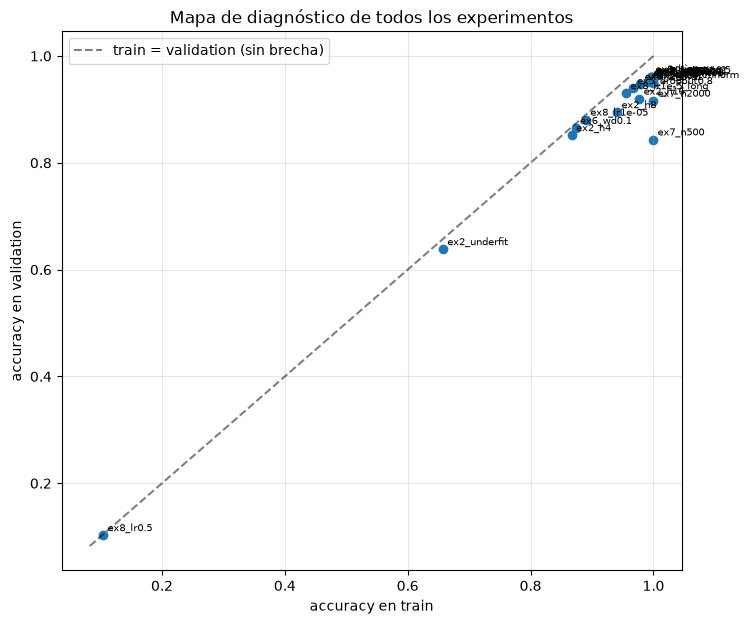

In [26]:
df = results_table()
display(df)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df['train_acc'], df['val_acc'])
lo = min(df['train_acc'].min(), df['val_acc'].min()) - 0.02
ax.plot([lo, 1.0], [lo, 1.0], 'k--', alpha=0.5, label='train = validation (sin brecha)')
for name, row in df.iterrows():
    ax.annotate(name, (row['train_acc'], row['val_acc']), fontsize=7,
                xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('accuracy en train')
ax.set_ylabel('accuracy en validation')
ax.set_title('Mapa de diagnóstico de todos los experimentos')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 🧠 Reflexión final

**1. Remedios comprobados**

| Si diagnostico… | Qué puedo hacer | Ejercicio donde lo comprobé |
|---|---|---|
| Underfitting | Aumentar capacidad: dos neuronas dan 63.80 % en validation; 64 dan 94.90 %. | 2 |
| Underfitting | Revisar lr o entrenar más: con 1e-5, pasar de 30 a 200 épocas mejora validation de 88.05 % a 93.00 %. | 8 |
| Overfitting | Elegir una parada temprana: la val loss baja de 0.3848 a 0.1820 al usar el mínimo de validación. | 4 |
| Overfitting | Agregar datos: la brecha baja de 15.65 a 4.15 pp. | 7 |
| Overfitting | Ajustar regularización: L2 0.01 reduce la val loss a 0.1747; con 0.1 aparece subajuste. Dropout tampoco mejora todas las métricas a la vez. | 5 y 6 |

**2. Diferencia entre underfitting y overfitting**

Para mí, underfitting es el estudiante que todavía no domina ni la práctica:
train y validation tienen errores altos. Overfitting es quien memoriza la práctica,
pero no traslada todo lo aprendido al simulacro. Las curvas me ayudan a distinguirlos:
en el primero ambas pérdidas siguen altas; en el segundo train mejora mientras
validation se separa o su loss empieza a subir. Una brecha pequeña por sí sola no basta.

**3. Cambio que más me sorprendió**

Me sorprendió el efecto de aumentar los datos: con 500 imágenes el modelo llega
a 100 % en train y solo 84.35 % en validation.
Con 8,000, validation alcanza 95.85 %.
Eso me muestra por qué aprender la práctica de memoria no garantiza generalizar.
También observé que una mejor accuracy puede coexistir con una peor loss.

**4. Papel de cada conjunto**

Uso train para actualizar los pesos; validation para elegir hiperparámetros y
parada; test para evaluar una sola vez el modelo ya elegido. Si mezclara muestras
entre conjuntos o ajustara el modelo después de mirar test, habría fuga de
información y el resultado parecería mejor de lo que sería con datos nuevos.

### ✅ Checklist de entrega

- [x] Completé el split y pasó la verificación: 8,000/2,000, sin solapamiento.
- [x] Ejecuté los 10 ejercicios en orden y guardé gráficas y tablas.
- [x] Cada ejercicio incluye diagnóstico, evidencia numérica, respuestas y conclusión.
- [x] Evalué el test una sola vez después de seleccionar el intento final.
- [x] Completé la reflexión final.
- [x] Ejecuté todo el código de principio a fin con un kernel nuevo, equivalente a Restart & Run All, sin errores.

Las respuestas se completaron usando las salidas guardadas de esa ejecución;
editar el texto no volvió a ejecutar el test. Los diagnósticos describen esta
corrida con semilla 42; no establecen umbrales universales.


In [27]:
from pathlib import Path
import json
evidence_dir = Path('evidencias')
evidence_dir.mkdir(exist_ok=True)
results_table().to_csv(evidence_dir / 'resumen_experimentos.csv')
(evidence_dir / 'historiales.json').write_text(
    json.dumps(RESULTS, ensure_ascii=False, indent=2), encoding='utf-8')
test_evidence = dict(selected_attempt=selected_attempt, config=FINAL_CONFIG,
                     train_acc=train_acc, val_acc=val_acc,
                     test_acc=test_acc, test_loss=test_loss)
(evidence_dir / 'evaluacion_final.json').write_text(
    json.dumps(test_evidence, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidencia exportada: tablas, historiales por época y evaluación final.')


Evidencia exportada: tablas, historiales por época y evaluación final.
